In [1]:
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Descriptors
from rdkit.Chem.rdMolDescriptors import CalcNumHBA
from rdkit.Chem.rdMolDescriptors import CalcNumHBD

import numpy as np
import pandas as pd

import os

# Data analysis

# Primary processd DB

In [2]:
#hand
hand = pd.read_csv('../collecting/primary_processed_PE_hex/hand_PE_hex.csv')
hand_567 = pd.read_csv('../collecting/primary_processed_PE_567/hand_PE_567.csv')
hand_567

,Smiles,elu1,elu2,ratio1,ratio2,Rf,title,doi,Rf_type
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.9,0.1,0.40,A Site-Specific Synthetic Route to Substituted...,10.1021/acs.orglett.3c03369,Q
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.7,0.3,0.05,A Site-Specific Synthetic Route to Substituted...,10.1021/acs.orglett.3c03369,Q
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.7,0.3,0.10,A Site-Specific Synthetic Route to Substituted...,10.1021/acs.orglett.3c03369,Q
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.7,0.3,0.65,A Site-Specific Synthetic Route to Substituted...,10.1021/acs.orglett.3c03369,Q
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.7,0.3,0.55,A Site-Specific Synthetic Route to Substituted...,10.1021/acs.orglett.3c03369,Q
...,...,...,...,...,...,...,...,...,...
4633,CC[C@H](NC(C)=O)c1ccc(COc2ccc3c(c2)CC[C@@H]2[C...,CCOC(C)=O,CCCCC.CCCCCC.CCCCCCC,0.5,0.5,0.30,Photochemical Alkylamination of Olefins throug...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
4634,CCOC(=O)CCC1(NC(C)=O)CCCCC1,CCOC(C)=O,CCCCC.CCCCCC.CCCCCCC,0.5,0.5,0.40,Photochemical Alkylamination of Olefins throug...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
4635,O=C1CCC2(CCCCC2)N1,CCOC(C)=O,CCCCC.CCCCCC.CCCCCCC,0.5,0.5,0.40,Photochemical Alkylamination of Olefins throug...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
4636,CCC(NC(C)=O)c1ccc(CN2CCN(c3ccccc3)CC2)cc1,CCOC(C)=O,CCCCC.CCCCCC.CCCCCCC,0.7,0.3,0.30,Photochemical Alkylamination of Olefins throug...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q


In [3]:
# intern_ SY
intern_sy = pd.read_csv('../collecting/primary_processed_PE_hex/intern_sy_PE_hex.csv')
intern_sy_567 = pd.read_csv('../collecting/primary_processed_PE_567/intern_sy_PE_567.csv')
intern_sy

,Smiles,elu1,elu2,ratio1,ratio2,Rf,title,doi,Rf_type
0,CP(C)(=O)[C@]12CCC[C@H]1CN(Cc1ccccc1)C2,ClCCl,CO,0.950000,0.050000,0.26,P(O)Me2–Alkenes: From Synthesis to Applications,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
1,C=C(c1cccc(OC)c1)P(C)(C)=O,ClCCl,CO,0.950000,0.050000,0.21,P(O)Me2–Alkenes: From Synthesis to Applications,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
2,CP(C)(=O)C1=C[C@H]2CC[C@@H](C1)N2C(=O)[O-],ClCCl,CO,0.950000,0.050000,0.18,P(O)Me2–Alkenes: From Synthesis to Applications,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
3,CP(C)(=O)C1=CCOC1,ClCCl,CO,0.950000,0.050000,0.23,P(O)Me2–Alkenes: From Synthesis to Applications,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
4,CP(C)(=O)C1=CCOC1,ClCCl,CO,0.950000,0.050000,0.26,P(O)Me2–Alkenes: From Synthesis to Applications,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
...,...,...,...,...,...,...,...,...,...
21241,C=CC1COC(c2ccccc2)c2c(-c3cccc4ccccc34)oc(-c3cc...,CCCCCC,CCOC(C)=O,0.975610,0.024390,0.15,Highly Regio- and Diastereoselective Synthesis...,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,C
21242,C=CC1COC(c2ccccc2)c2c(-c3cccc4ccccc34)oc(-c3cc...,CCCCCC,CCOC(C)=O,0.975610,0.024390,0.19,Highly Regio- and Diastereoselective Synthesis...,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,C
21243,C=C[C@H]1CO[C@@H](c2ccc(C#N)cc2)c2c(-c3ccccc3)...,CCOC(C)=O,CCCCCC,0.950000,0.050000,0.30,Highly Regio- and Diastereoselective Synthesis...,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,C
21244,C=C[C@H]1CO[C@@H](c2ccccc2)c2c(-c3ccccc3)oc(-c...,CCCCCC,CCOC(C)=O,0.952381,0.047619,0.13,Highly Regio- and Diastereoselective Synthesis...,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,C


In [4]:
# intern_KMS
intern_ms = pd.read_csv('../collecting/primary_processed_PE_hex/intern_ms_PE_hex.csv')
intern_ms_567 = pd.read_csv('../collecting/primary_processed_PE_567/intern_ms_PE_567.csv')
intern_ms

,Smiles,elu1,elu2,ratio1,ratio2,Rf,title,doi,Rf_type
0,C=C/C=C/CCC/C=C/C(=O)N(C)OC,CCOC(C)=O,CCCCC,0.50,0.50,0.33,Chiral Ruthenium Lewis Acid Catalyzed Intramol...,https://pubs.acs.org/doi/10.1021/ol1019103,C
1,COC[C@@H]1CCCN1/N=C/[C@@H]1CC=C[C@@H]2CCC[C@H]21,CCCCC,CCOCC,0.80,0.20,0.26,Chiral Ruthenium Lewis Acid Catalyzed Intramol...,https://pubs.acs.org/doi/10.1021/ol1019103,C
2,C=C/C=C/CCC/C=C/C(C)=O,CCCCC,CCOC(C)=O,0.95,0.05,0.19,Chiral Ruthenium Lewis Acid Catalyzed Intramol...,https://pubs.acs.org/doi/10.1021/ol1019103,C
3,O=C[C@@H]1CC=C[C@@H]2CCC[C@@H]12,CCCCC,CCOCC,0.95,0.05,0.22,Chiral Ruthenium Lewis Acid Catalyzed Intramol...,https://pubs.acs.org/doi/10.1021/ol1019103,C
4,C[C@@]1(C=O)CC=C[C@@H]2CCC[C@H]21,CCCCC,CCOCC,0.90,0.10,0.36,Chiral Ruthenium Lewis Acid Catalyzed Intramol...,https://pubs.acs.org/doi/10.1021/ol1019103,C
...,...,...,...,...,...,...,...,...,...
3778,COC(=O)c1ccc(N2C(=O)CN(Cc3ccccc3)C(=O)C2C)cc1OC,CCOC(C)=O,NaN,1.00,0.00,0.48,Synthesis of Tricyclic Nitrogen Heterocycles b...,https://pubs.acs.org/doi/10.1021/ol2031763,C
3779,COC(=O)c1cc(Br)c(N2C(=O)CN(Cc3ccccc3)C(=O)C2C)...,CCOC(C)=O,C1CCCCC1,0.90,0.10,0.29,Synthesis of Tricyclic Nitrogen Heterocycles b...,https://pubs.acs.org/doi/10.1021/ol2031763,C
3780,COC(=O)c1cc(Br)c(N2C(=O)CCC2C)cc1OC,CCOC(C)=O,NaN,1.00,0.00,0.27,Synthesis of Tricyclic Nitrogen Heterocycles b...,https://pubs.acs.org/doi/10.1021/ol2031763,C
3781,COC(=O)c1cc(Br)c(N2C(=O)CCCC2C)cc1OC,CCOC(C)=O,NaN,1.00,0.00,0.23,Synthesis of Tricyclic Nitrogen Heterocycles b...,https://pubs.acs.org/doi/10.1021/ol2031763,C


In [5]:
# org_syn
org_syn = pd.read_csv('../collecting/primary_processed_PE_hex/Org_syn_PE_hex.csv')
org_syn_567 = pd.read_csv('../collecting/primary_processed_PE_567/Org_syn_PE_567.csv')

# 칼럼명 맞춰주기
org_syn['title'] = [np.nan for i in range(len(org_syn))]
org_syn = org_syn.rename(columns={'link': 'doi'})
org_syn = org_syn[['Smiles', 'elu1', 'elu2', 'ratio1', 'ratio2', 'Rf', 'title', 'doi','Rf_type']]

org_syn_567['title'] = [np.nan for i in range(len(org_syn))]
org_syn_567 = org_syn_567.rename(columns={'link': 'doi'})
org_syn_567 = org_syn_567[['Smiles', 'elu1', 'elu2', 'ratio1', 'ratio2', 'Rf', 'title', 'doi','Rf_type']]


# !!! org_syn은 모두 valid하다는 가정으로 모두 C_Rf라고 가정할 경우 !!!
org_syn_567['Rf_type'] = ['C' for i in range(len(org_syn_567))]
org_syn['Rf_type'] = ['C' for i in range(len(org_syn))]
org_syn

,Smiles,elu1,elu2,ratio1,ratio2,Rf,title,doi,Rf_type
0,C[C@H](CCC=O)[C@H]1CC[C@H]2[C@@H]3CCC4CCCC[C@]...,c1ccccc1,NaN,1.0,0.0,0.76,NaN,https://www.orgsyn.org/demo.aspx?prep=CV5P0242,C
1,C[C@H](CCCO)[C@H]1CC[C@H]2[C@@H]3CCC4CCCC[C@]4...,c1ccccc1,NaN,1.0,0.0,0.19,NaN,https://www.orgsyn.org/demo.aspx?prep=CV5P0242,C
2,ON=C(Cc1ccccc1)Cc1ccccc1,ClC(Cl)Cl,CO,95.0,5.0,0.80,NaN,https://www.orgsyn.org/demo.aspx?prep=CV5P0083,C
3,C1CN1,ClC(Cl)Cl,CO,95.0,5.0,0.80,NaN,https://www.orgsyn.org/demo.aspx?prep=CV5P0083,C
4,CC(C)(C)OC(=O)C=[N+]=[N-],ClC(Cl)Cl,NaN,1.0,0.0,0.72,NaN,https://www.orgsyn.org/demo.aspx?prep=CV5P0179,C
...,...,...,...,...,...,...,...,...,...
1373,Nc1ccccc1CO,CCCCCC,CCOC(C)=O,0.7,0.3,0.10,NaN,https://www.orgsyn.org/demo.aspx?prep=v87p0339,C
1374,O=Cc1ccccc1[N+](=O)[O-],CCCCCC,CCOC(C)=O,0.7,0.3,0.43,NaN,https://www.orgsyn.org/demo.aspx?prep=v87p0339,C
1375,O=[N+]([O-])c1ccccc1CNc1ccccc1CO,CCCCCC,CCOC(C)=O,0.7,0.3,0.26,NaN,https://www.orgsyn.org/demo.aspx?prep=v87p0339,C
1376,c1ccc2c(c1)COc1c3ccccc3nn1-2,CCCCCC,CCOC(C)=O,0.7,0.3,0.45,NaN,https://www.orgsyn.org/demo.aspx?prep=v87p0339,C


In [6]:
# gpt 
gpt = pd.read_csv('../collecting/primary_processed_PE_hex/gpt_PE_hex.csv')

gpt_567 = pd.read_csv('../collecting/primary_processed_PE_567/gpt_PE_567.csv')

gpt_567

,Smiles,elu1,elu2,ratio1,ratio2,Rf,title,doi,Rf_type
0,COc1ccc(C#Cc2ccccc2C(=O)/C=C/c2ccc(I)cc2)cc1,CCCCCC,CCOC(C)=O,0.995000,0.005000,0.2,Phosphine-Based Porous Organic Polymer-Stabili...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
1,O=C1C(c2ccccc2)=C(c2ccccc2)c2ccccc21,CCCCCC,CCOC(C)=O,0.950000,0.050000,0.5,Phosphine-Based Porous Organic Polymer-Stabili...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
2,COc1ccc(C2=C(c3ccc(OC)cc3)c3ccccc3C2=O)cc1,CCCCCC,CCOC(C)=O,0.950000,0.050000,0.4,Phosphine-Based Porous Organic Polymer-Stabili...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
3,O=C1C(c2ccc(F)cc2)=C(c2ccc(F)cc2)c2ccccc21,CCCCCC,CCOC(C)=O,0.950000,0.050000,0.4,Phosphine-Based Porous Organic Polymer-Stabili...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
4,O=C1C(c2ccc(C(F)(F)F)cc2)=C(c2ccc(C(F)(F)F)cc2...,CCCCCC,CCOC(C)=O,0.950000,0.050000,0.4,Phosphine-Based Porous Organic Polymer-Stabili...,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,Q
...,...,...,...,...,...,...,...,...,...
23853,CC(C)OC(=O)C1=Cc2cc(Br)ccc2C(=[N+]=[N-])C1=O,CCCCC.CCCCCC.CCCCCCC,CCOC(C)=O,0.750000,0.250000,0.2,Atroposelective Synthesis of Axially Chiral C2...,https://pubs.acs.org/doi/10.1021/acs.orglett.2...,Q
23854,CCCc1c(-c2c(O)c(C(=O)OC)cc3ccccc23)n(C)c2cc(C)...,CCCCC.CCCCCC.CCCCCCC,CCOC(C)=O,0.952381,0.047619,0.4,Atroposelective Synthesis of Axially Chiral C2...,https://pubs.acs.org/doi/10.1021/acs.orglett.2...,Q
23855,COC(=O)c1cccc2c1C=CC(=O)C2=[N+]=[N-],CCCCC.CCCCCC.CCCCCCC,CCOC(C)=O,0.833333,0.166667,0.3,Atroposelective Synthesis of Axially Chiral C2...,https://pubs.acs.org/doi/10.1021/acs.orglett.2...,Q
23856,CCCc1c(-c2c(O)ccc3c(C(=O)OC)cccc23)n(C)c2cc(C)...,CCCCC.CCCCCC.CCCCCCC,CCOC(C)=O,0.952381,0.047619,0.2,Atroposelective Synthesis of Axially Chiral C2...,https://pubs.acs.org/doi/10.1021/acs.orglett.2...,Q


In [8]:
## d4c 데이터 합
# d4c_all  = pd.concat([hand, intern_sy, intern_ms, org_syn, gpt], axis=0, ignore_index=True)
# d4c_all_567 = pd.concat([hand_567, intern_sy_567, intern_ms_567, org_syn_567, gpt_567], axis=0, ignore_index=True)

# d4c_all  = pd.concat([hand, intern_sy, intern_ms, gpt], axis=0, ignore_index=True)
# d4c_all_567 = pd.concat([hand_567, intern_sy_567, intern_ms_567, gpt_567], axis=0, ignore_index=True)

# d4c_all  = pd.concat([hand, intern_sy, org_syn, gpt], axis=0, ignore_index=True)
# d4c_all_567 = pd.concat([hand_567, intern_sy_567, org_syn_567, gpt_567], axis=0, ignore_index=True)

d4c_all  = pd.concat([hand, intern_sy, gpt], axis=0, ignore_index=True)
d4c_all_567 = pd.concat([hand_567, intern_sy_567, gpt_567], axis=0, ignore_index=True)


data_source = ['D4C' for i in range(len(d4c_all))]
d4c_all['DataSource'] = data_source
d4c_all_567['DataSource'] = data_source

d4c_all = d4c_all[['Smiles', 'elu1', 'elu2', 'ratio1', 'ratio2', 'Rf', 'Rf_type', 'DataSource', 'doi']]
d4c_all_567 = d4c_all_567[['Smiles', 'elu1', 'elu2', 'ratio1', 'ratio2', 'Rf', 'Rf_type', 'DataSource', 'doi']]

d4c_all.columns = ['Smiles', 'elu1_smiles', 'elu2_smiles', 'ratio1', 'ratio2', 'Rf', 'Rf_type', 'DataSource', 'doi']
d4c_all_567.columns = ['Smiles', 'elu1_smiles', 'elu2_smiles', 'ratio1', 'ratio2', 'Rf', 'Rf_type', 'DataSource', 'doi']
d4c_all

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.900000,0.100000,0.40,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.05,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.10,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.65,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.55,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
49737,CC(C)OC(=O)C1=Cc2cc(Br)ccc2C(=[N+]=[N-])C1=O,CCCCCC,CCOC(C)=O,0.750000,0.250000,0.20,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
49738,CCCc1c(-c2c(O)c(C(=O)OC)cc3ccccc23)n(C)c2cc(C)...,CCCCCC,CCOC(C)=O,0.952381,0.047619,0.40,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
49739,COC(=O)c1cccc2c1C=CC(=O)C2=[N+]=[N-],CCCCCC,CCOC(C)=O,0.833333,0.166667,0.30,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
49740,CCCc1c(-c2c(O)ccc3c(C(=O)OC)cccc23)n(C)c2cc(C)...,CCCCCC,CCOC(C)=O,0.952381,0.047619,0.20,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...


In [9]:
# nat.comm
nat = pd.read_csv('../collecting/primary_processed_PE_hex/nat_commun_raw_PE_hex.csv')
nat_567 = pd.read_csv('../collecting/primary_processed_PE_567/nat_commun_raw_PE_567.csv')

data_source = ['benchmark' for i in range(len(nat))]
nat['DataSource']=data_source
nat_567['DataSource']=data_source
doi_column = ['exp (benchmark' for i in range(len(nat))]
nat['doi']=doi_column
nat_567['doi']=doi_column
nat



,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,O=C(CCCl)c1ccccc1,CCCCCC,NaN,1.000000,0.000000,0.049175,C,benchmark,exp (benchmark
1,O=C(CCCl)c1ccccc1,CCCCCC,CCOC(C)=O,0.980392,0.019608,0.262708,C,benchmark,exp (benchmark
2,O=C(CCCl)c1ccccc1,CCCCCC,CCOC(C)=O,0.952381,0.047619,0.410200,C,benchmark,exp (benchmark
3,O=C(CCCl)c1ccccc1,CCCCCC,CCOC(C)=O,0.833333,0.166667,0.719773,C,benchmark,exp (benchmark
4,O=C(CCCl)c1ccccc1,CCCCCC,CCOC(C)=O,0.750000,0.250000,0.794856,C,benchmark,exp (benchmark
...,...,...,...,...,...,...,...,...,...
4854,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.666667,0.333333,0.498683,C,benchmark,exp (benchmark
4855,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.500000,0.500000,0.662423,C,benchmark,exp (benchmark
4856,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
4857,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.500000,0.500000,0.010664,C,benchmark,exp (benchmark


In [10]:
## 전체 데이터 합
united  = pd.concat([d4c_all, nat], axis=0, ignore_index=True)
united_567 = pd.concat([d4c_all_567, nat_567], axis=0, ignore_index=True)
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.900000,0.100000,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.700000,0.300000,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54596,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.666667,0.333333,0.498683,C,benchmark,exp (benchmark
54597,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.500000,0.500000,0.662423,C,benchmark,exp (benchmark
54598,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54599,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.500000,0.500000,0.010664,C,benchmark,exp (benchmark


In [11]:
# ratio 부피비 --> 몰로 단위로 변경 및 정규화 

from rdkit.Chem import Descriptors as D
from tqdm.auto import tqdm

def vol_2_mol_ratio(df, ver):
    # ver : 'hex' or '567'
    elu_inform = pd.read_csv('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/DB/data_process/eluent_standard.csv')
    d_converter = dict(zip(elu_inform['hex_Smiles'], elu_inform['density']))
    d_converter_567 = dict(zip(elu_inform['567_Smiles'], elu_inform['density']))

    for i in tqdm(range(len(df))):
        smiles1 = df.loc[i, 'elu1_smiles']
        ratio1 = df.loc[i, 'ratio1']
        smiles2 = df.loc[i, 'elu2_smiles']
        ratio2 = df.loc[i, 'ratio2']

        if ver == 'hex':
            converter = d_converter
        elif ver == '567':
            converter = d_converter_567

        if pd.notna(smiles1):
            df.at[i, 'ratio1'] = ratio1 * converter[smiles1] / D.MolWt(Chem.MolFromSmiles(smiles1))
        if pd.notna(smiles2):
            df.at[i, 'ratio2'] = ratio2 * converter[smiles2] / D.MolWt(Chem.MolFromSmiles(smiles2))

    # 몰 비 정규화
    ratio_total = df[['ratio1', 'ratio2']].sum(axis=1)
    df['ratio1'] = round((df['ratio1'] / ratio_total),6)
    df['ratio2'] = round((df['ratio2'] / ratio_total),6)
    # df['ratio1'] = (df['ratio1'] / ratio_total)
    # df['ratio2'] = (df['ratio2'] / ratio_total)

    return df


#---------PE hex 버전------------

united = vol_2_mol_ratio(united, ver = 'hex')

#---------PE 567 버전------------

united_567 = vol_2_mol_ratio(united_567, ver = '567')




  0%|          | 0/54601 [00:00<?, ?it/s]

  0%|          | 0/54601 [00:00<?, ?it/s]

In [12]:
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54596,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.614610,0.385390,0.498683,C,benchmark,exp (benchmark
54597,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.443636,0.556364,0.662423,C,benchmark,exp (benchmark
54598,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54599,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.443636,0.556364,0.010664,C,benchmark,exp (benchmark


## Filtering & 중복제거

In [13]:
# 일단 PE_567 데이터 셋에서 중복 데이터 중 Rf 이상치 골라내고 (2개 중복인데 그 차이가 큰거는 삭제)
# 골라낸 인덱스 가지고 PE_hex 데이터 셋에서도 삭제하기

In [14]:
'''
## 데이터 쌍 간 거리 기준으로 이상치 하나만 찾기

# 거리 정방행렬 만들기 (절대값 차이) 
dist_matrix = squareform(pdist(rf_values.reshape(-1, 1), metric='euclidean'))

# 각 샘플의 평균 거리 계산
avg_dist = dist_matrix.mean(axis=1)

# 평균 거리 기준 이상치 찾기
outlier_idx = np.argmax(avg_dist)
no_outlier = np.delete(avg_dist, outlier_idx)
if np.std(rf_values) > 0.01 and avg_dist[outlier_idx] > np.mean(no_outlier) * 1.2:
    # 하나만 이상하게 멀리 떨어져 있으면 삭제
    delete_indices.append(indices[outlier_idx])
    delete_data_id.append(data_id)
'''

# update

from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster
import numpy as np
from rich import print as richprint

def filtering_garbage(dataframe, clustering_n):

    delete_indices = []
    delete_data_id = []
    ambiguous_indices = []
    ambiguous_data_id = []
    
    for data_id, group in dataframe.groupby(['Smiles','elu1_smiles','elu2_smiles','ratio1','ratio2'], as_index=True):
        if len(group) == 1:
            continue
    
        rf_values = group['Rf'].values
        indices = group.index.tolist()
            
        if len(group) == 2:
            if np.abs(rf_values[0]-rf_values[1]) >= 0.1:
                delete_indices.extend(indices)
                delete_data_id.append(data_id)
            else:
                continue
    
        else:
            hierarchical_cluster = linkage(rf_values.reshape(-1,1), method = 'complete')
            # method = complete : 계층적cluster내 클러스터간 거리 구할때 데이터 중 최장거리 기준으로 거리를 구함
            cluster_label = fcluster(hierarchical_cluster, t=clustering_n, criterion='distance')
            # cluster간 거리 0.1 이상이면(최장거리 기준) 다른 클러스터로 취급 --> 0.05 기준으로 재필터링
            clusters, cluster_size = np.unique(cluster_label, return_counts = True)
        
            if len(clusters) >= 2 and (np.max(cluster_size) < np.sum(cluster_size)*0.7):
                ambiguous_data_id.append(data_id)
                ambiguous_indices.extend(indices)
                
            else:
                if len(clusters) == 1:
                    continue
                else:
                    # len(clusters) >= 2 and (np.max(cluster_size) > np.sum(cluster_size)*0.7) 인 케이스
                    # 젤 큰 사이즈의 클러스터가 전체의 70% 이상이면 나머지는 버리도록
                    major_cluster_label = clusters[np.argmax(cluster_size)]
                    minor_mask = (cluster_label != major_cluster_label)

                    for idx in np.array(indices)[minor_mask]:
                        delete_indices.append(idx)
                        delete_data_id.append(data_id)

    
    # 결과 표시
    richprint(f"[bold bright_red]삭제할 이상치 인덱스 {len(delete_indices)}개[/bold bright_red]: {delete_indices}")
    richprint("[bold orange1]삭제할 이상치 data_id:[/bold orange1]")
    for d in delete_data_id:
        print(d)
    richprint(f"[bold green1]애매한 data_id {len(ambiguous_indices)}개 (수동 확인 필요):[/bold green1]")
    for d in ambiguous_data_id:
        print(d)
    richprint('[bold bright_red]!!아직 삭제하지 않았고, 삭제 후 인덱스 정렬 필요!![/bold bright_red]')

    return delete_indices, delete_data_id, ambiguous_indices, ambiguous_data_id

In [15]:
delete_indices, delete_data_id, ambiguous_indices, ambiguous_data_id = filtering_garbage(united_567, clustering_n=0.05)

삭제할 이상치 인덱스 342개: [45759, 45760, 49402, 49403, 49442, 49443, 17436, 17437, 40390, 40391, 48531, 48532, 
49027, 49028, 13546, 50574, 52402, 53862, 52401, 53861, 53150, 53516, 53149, 53515, 53148, 53514, 52217, 53300, 
52216, 53299, 52043, 52588, 52042, 52587, 52041, 52586, 27681, 27682, 18667, 18668, 23111, 23112, 19312, 19313, 
39248, 39249, 9531, 9532, 3088, 3089, 18341, 18342, 13045, 13046, 13048, 13049, 7676, 7677, 4756, 4757, 12087, 
12088, 33838, 33839, 3867, 39276, 21641, 21642, 13297, 13301, 39571, 39572, 12893, 12894, 1216, 1217, 46498, 46499,
41281, 51394, 19316, 19317, 9140, 9141, 2517, 2534, 1955, 8495, 12340, 12341, 12084, 12085, 36116, 36117, 40485, 
40486, 52414, 53880, 52413, 53879, 42746, 42747, 23622, 23623, 5828, 5854, 17585, 17586, 13593, 13594, 13595, 
13596, 13574, 13575, 41370, 41371, 21872, 36307, 13798, 13799, 810, 815, 34301, 34302, 35241, 35242, 45793, 45794, 
29433, 29434, 5521, 5522, 52407, 53885, 52397, 53839, 52396, 53838, 52395, 53837, 23069, 40732, 19434, 19435, 
18351, 18352, 492, 493, 40547, 40548, 21311, 21312, 14106, 18005, 23733, 24077, 17423, 17424, 29411, 29412, 29413, 
29414, 23027, 23028, 42323, 51702, 38644, 38645, 2484, 9072, 46259, 46260, 40031, 40032, 52792, 52840, 5539, 5540, 
36975, 36976, 43321, 43322, 28051, 28052, 11972, 11973, 14108, 42214, 42215, 53307, 53427, 53304, 53424, 22418, 
22419, 40848, 40849, 40842, 40843, 11676, 11677, 11652, 11653, 45765, 45766, 14899, 14900, 32896, 32897, 42042, 
42043, 2489, 9084, 32812, 41021, 22415, 22416, 46311, 46337, 24246, 24247, 22412, 22413, 13629, 13630, 1862, 1863, 
18510, 18511, 12076, 12077, 52608, 53170, 14111, 51907, 51930, 51906, 51929, 51905, 51928, 51904, 51927, 51903, 
51926, 51908, 51931, 53967, 54003, 53966, 54002, 53965, 54001, 53964, 54000, 53963, 53999, 42771, 50733, 54029, 
54570, 54030, 54569, 46293, 46322, 36817, 36818, 17882, 50380, 52531, 53756, 52530, 53755, 52529, 53754, 52528, 
53753, 52527, 53752, 12070, 12071, 42470, 42471, 54035, 54361, 54036, 54360, 51994, 52581, 31230, 31231, 31232, 
31233, 1225, 1226, 37073, 37074, 23037, 23038, 38811, 38812, 52788, 52854, 33728, 33729, 52230, 53547, 52229, 
53546, 52228, 53545, 52227, 53544, 12168, 12169, 18630, 18631, 52051, 53818, 52050, 53817, 52049, 53816, 52048, 
53815, 52047, 53814, 53799, 53834, 53717, 53969, 52487, 53624, 23301, 23302, 43345, 43346, 43343, 43344, 18515, 
18516, 1330, 26383]

삭제할 이상치 data_id:

('C#CC/C(=C/[C@H](C)[C@H](O[Si](CC)(CC)CC)c1ccccc1)[Si](C)(C)c1ccccc1', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.882244, 0.117756)
('C=C(Br)C[C@@]1(c2ccccc2)CCC[C@](C)(c2c[nH]c3ccccc23)C1=O', 'CCCCCC', 'ClCCl', 0.328775, 0.671225)
('C=C(CCCCCC)COC1=C(C)CCCC1(O)c1ccccc1', 'CCCCCC', 'CCOC(C)=O', 0.749803, 0.250197)
('C=C1[C@H](O[Si](C)(C)C(C)(C)C)CC[C@]2(C)[C@H]3CCC4=C(CCO)CC[C@H]4[C@]3(C)[C@@H](OC(C)=O)C[C@@H]12', 'CCCCCC', 'CCOC(C)=O', 0.749803, 0.250197)
('C=CCOC(=O)C(=C)CC(I)C(F)(F)F', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.882244, 0.117756)
('C=CCOc1c(C)cccc1C(=C)c1ccccc1', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.833187, 0.166813)
('CC(=O)OC(c1ccccc1)C1COC(C(F)(F)F)N1C(=O)OCc1ccccc1', 'CCCCC', 'CCOC(C)=O', 0.884089, 0.115911)
('CC(=O)Oc1ccc(C=O)cc1', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.833187, 0.166813)
('CC(=O)Oc1ccccc1', 'ClCCl', 'CO', 0.969397, 0.030603)
('CC(=O)Oc1ccccc1', 'ClCCl', 'CO', 0.984461, 0.015539)
('CC(=O)c1ccc(I)cc1', 'ClCCl', 'CO', 0.950015, 0.049985)
('CC(=O)c1ccc(I

애매한 data_id 198개 (수동 확인 필요):

('Brc1ccc2ccccc2c1', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.9615, 0.0385)
('C/C(=C\\C(=O)c1cccc(Br)c1)N(C)C', 'CCCCCC', 'CCOC(C)=O', 0.428314, 0.571686)
('C=CC#CCSc1ccc(C)cc1', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.714071, 0.285929)
('C=C[C@@]1(C)CC[C@@H](C(=C)CO[Si](C)(C)C(C)(C)C)C[C@@]1(O)C(=C)C', 'CCCCC.CCCCCC.CCCCCCC', 'CCOCC', 0.726623, 0.273377)
('CC(=O)NC(C)COc1c(C)cc(-[s+]2c3ccccc3c3ccccc32)cc1C.F[B-](F)(F)F', 'ClCCl', 'CO', 0.926851, 0.073149)
('CC(=O)OC1=C2CC(C#N)C2CCC1', 'CCCCCC', 'CCOC(C)=O', 0.749803, 0.250197)
('CC(=O)OC1=C2CC(C(C)=O)C2CCC1', 'CCCCCC', 'CCOC(C)=O', 0.692083, 0.307917)
('CC(=O)OC[C@H]1O[C@@H](C2=CCCc3ccccc32)[C@H](OC(C)=O)[C@@H]1OC(C)=O', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.428314, 0.571686)
('CC(C)(C)C(=O)OC1=C2CC(c3ccccc3C(F)(F)F)C2CCC1', 'CCCCCC', 'CCOC(C)=O', 0.937438, 0.062562)
('CC(C)(C)OC(=O)N1CCCC1C(C#N)=NOCc1ccccc1', 'CCCCC.CCCCCC.CCCCCCC', 'CC(C)=O', 0.630267, 0.369733)
('CC(C)(C)c1ccc(C#N)cc1', 'CCCCC.CCCCCC.CCCCCCC', 'CCOC(C)=O', 0.925854, 

!!아직 삭제하지 않았고, 삭제 후 인덱스 정렬 필요!!

In [16]:
# 삭제할 애들 확인해보기
index = 50
mask = (united_567.iloc[:, 0:5].fillna('nan') == united_567.iloc[delete_indices[index], 0:5].fillna('nan')).all(axis=1)
united_567[mask]


,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
18341,CC(C)=CCCC1(C)CCC=CCC(=O)C1C(=O)OCC[Si](C)(C)C,CCCCC,ClCCl,0.356524,0.643476,0.30,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
18342,CC(C)=CCCC1(C)CCC=CCC(=O)C1C(=O)OCC[Si](C)(C)C,CCCCC,ClCCl,0.356524,0.643476,0.43,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...


In [17]:
# 애매한 애들 확인해보기
index = 10
mask = (united_567.iloc[:, 0:5].fillna('nan') == united_567.iloc[ambiguous_indices[index], 0:5].fillna('nan')).all(axis=1)
united_567[mask]

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
28976,C=C[C@@]1(C)CC[C@@H](C(=C)CO[Si](C)(C)C(C)(C)C...,CCCCC.CCCCCC.CCCCCCC,CCOCC,0.726623,0.273377,0.55,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
28977,C=C[C@@]1(C)CC[C@@H](C(=C)CO[Si](C)(C)C(C)(C)C...,CCCCC.CCCCCC.CCCCCCC,CCOCC,0.726623,0.273377,0.61,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
44208,C=C[C@@]1(C)CC[C@@H](C(=C)CO[Si](C)(C)C(C)(C)C...,CCCCC.CCCCCC.CCCCCCC,CCOCC,0.726623,0.273377,0.55,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
44209,C=C[C@@]1(C)CC[C@@H](C(=C)CO[Si](C)(C)C(C)(C)C...,CCCCC.CCCCCC.CCCCCCC,CCOCC,0.726623,0.273377,0.61,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...


In [18]:
# 중복 제거 (평균)하기 전에 이상치 제거!

delete_list = list(set(delete_indices)|set(ambiguous_indices))

united_f = united.drop(delete_list, axis=0)
united_f = united_f.reset_index(drop=True)

united_567_f = united_567.drop(delete_list, axis=0)
united_567_f = united_567_f.reset_index(drop=True)

In [19]:
united_f

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54056,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.614610,0.385390,0.498683,C,benchmark,exp (benchmark
54057,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.443636,0.556364,0.662423,C,benchmark,exp (benchmark
54058,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54059,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.443636,0.556364,0.010664,C,benchmark,exp (benchmark


# 저장 전에 덮어쓰지 않게 이름 확인 !!!!

In [20]:
united_f.to_csv('../collecting/filtered_data/united_filter_no_drop_dup.csv', index=False)
united_567_f.to_csv('../collecting/filtered_data/united_filter_567_no_drop_dup.csv', index=False)

In [17]:
# 중복 제거!!
# 중복 데이터 평균 내기
# D4C 이랑 benchmark에서 겹치는거 있으면 데이터소스는 d4c으로 처리하는 중


#--------PE hex---------
united_f_d = united_f.groupby(by = ['Smiles','elu1_smiles','elu2_smiles','ratio1','ratio2'] , as_index = False).agg({'Rf': 'mean','DataSource': 'first'})

#=--------PE 567------------
united_567_f_d = united_567_f.groupby(by = ['Smiles','elu1_smiles','elu2_smiles','ratio1','ratio2'], as_index = False).agg({'Rf': 'mean','DataSource': 'first'})


united_f_d

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,DataSource
0,BC[C@@]12CC(C(=O)OC)(C(=O)OC)C[C@@H]1C2(C)C.CN...,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.20,D4C
1,BC[C@@]12CC(C(=O)OC)(C(=O)OC)C[C@@H]1[C@H]2c1c...,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.20,D4C
2,BC[C@@]12CC(C(=O)OC)(C(=O)OC)C[C@@H]1[C@H]2c1c...,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.20,D4C
3,BC[C@@]12CC(C(=O)OC)(C(=O)OC)C[C@@H]1[C@H]2c1c...,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.20,D4C
4,BC[C@@]12CC(C(=O)OC)(C(=O)OC)C[C@@H]1[C@H]2c1c...,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.20,D4C
...,...,...,...,...,...,...,...
43956,c1csc(C2CCCCN2)c1,CCOC(C)=O,CO,0.788480,0.211520,0.24,D4C
43957,c1csc(C2CCOC2)c1,CCCCCC,CCOC(C)=O,0.428314,0.571686,0.66,D4C
43958,c1csc(CN2CCOCC2)c1,CCCCCC,CCOC(C)=O,0.529149,0.470851,0.30,D4C
43959,c1ncc(-c2ccc(CN3CCOCC3)cc2)cn1,ClCCl,CO,0.893808,0.106192,0.29,D4C


In [18]:
united_f_d[united_f_d['DataSource']=='benchmark']

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,DataSource
36,BrCCCc1ccccc1,CCCCCC,CCOC(C)=O,0.692083,0.307917,0.983394,benchmark
37,BrCCCc1ccccc1,CCCCCC,CCOC(C)=O,0.789298,0.210702,0.934233,benchmark
38,BrCCCc1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.861065,benchmark
39,BrCCCc1ccccc1,CCCCCC,CCOC(C)=O,0.973999,0.026001,0.697842,benchmark
40,BrCCCc1ccccc1,CCCCCC,CCOCC,0.443636,0.556364,0.979465,benchmark
...,...,...,...,...,...,...,...
43934,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,benchmark
43935,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,benchmark
43936,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,benchmark
43937,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,benchmark


In [19]:
delete_indices, delete_data_id, ambiguous_indices, ambiguous_data_id = filtering_garbage(united_f, clustering_n=0.05)

삭제할 이상치 인덱스 12개: [13965, 49927, 13431, 50797, 17852, 49874, 13437, 50311, 706, 23918, 307, 13444]

삭제할 이상치 data_id:

('COc1cccc(C#N)c1', 'CCCCCC', 'CCOC(C)=O', 0.973999, 0.026001)
('Cc1ccc(C=O)cc1', 'CCCCCC', 'CCOC(C)=O', 0.973999, 0.026001)
('N#Cc1cccc2ccccc12', 'CCCCCC', 'CCOC(C)=O', 0.973999, 0.026001)
('O=C(C(=O)c1ccccc1)c1ccccc1', 'CCCCCC', 'CCOC(C)=O', 0.973999, 0.026001)
('O=C(Nc1ccccc1)c1ccccc1', 'CCCCCC', 'CCOC(C)=O', 0.789299, 0.210701)
('O=Cc1ccc2ccccc2n1', 'CCCCCC', 'CCOC(C)=O', 0.870849, 0.129151)


애매한 data_id 12개 (수동 확인 필요):

('CC(c1ccccc1C(=O)NC(C)(C)C)C(N=C(c1ccccc1)c1ccccc1)c1ccccc1', 'CCCCCC', 'CCOC(C)=O', 0.749803, 0.250197)
('CCOC(=S)Sc1cc(C)c(OCCCC(C)(C)C(=O)OC)cc1C', 'CCCCCC', 'CCOC(C)=O', 0.882244, 0.117756)
('COc1ccc(NC(=O)c2ccccc2)cc1', 'CCCCCC', 'CCOC(C)=O', 0.749803, 0.250197)
('Cn1cc(C(=O)c2ccccc2)c2ccccc21', 'CCCCCC', 'CCOC(C)=O', 0.749803, 0.250197)


!!아직 삭제하지 않았고, 삭제 후 인덱스 정렬 필요!!

In [ ]:
'''
a= [df for id, df in united.groupby(by = ['Smiles','elu1_smiles','elu2_smiles','ratio1','ratio2'] , as_index = False) if len(df)>=7]
len(a)
a[0]

'''

In [20]:
united_567

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54596,CC1CCC(=O)c2ccccc21,CCCCC.CCCCCC.CCCCCCC,CCOCC,0.347084,0.652916,0.498683,C,benchmark,exp (benchmark
54597,CC1CCC(=O)c2ccccc21,CCCCC.CCCCCC.CCCCCCC,CCOCC,0.209983,0.790017,0.662423,C,benchmark,exp (benchmark
54598,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54599,O=C1CCCc2cccnc21,CCCCC.CCCCCC.CCCCCCC,CCOCC,0.209983,0.790017,0.010664,C,benchmark,exp (benchmark


In [21]:
united_f_d.to_csv('../collecting/filtered_data/united_filtered.csv',index=False)
united_567_f_d.to_csv('../collecting/filtered_data/united_567filtered.csv',index=False)

## analysis

100%|██████████| 107467/107467 [01:04<00:00, 1661.64it/s]


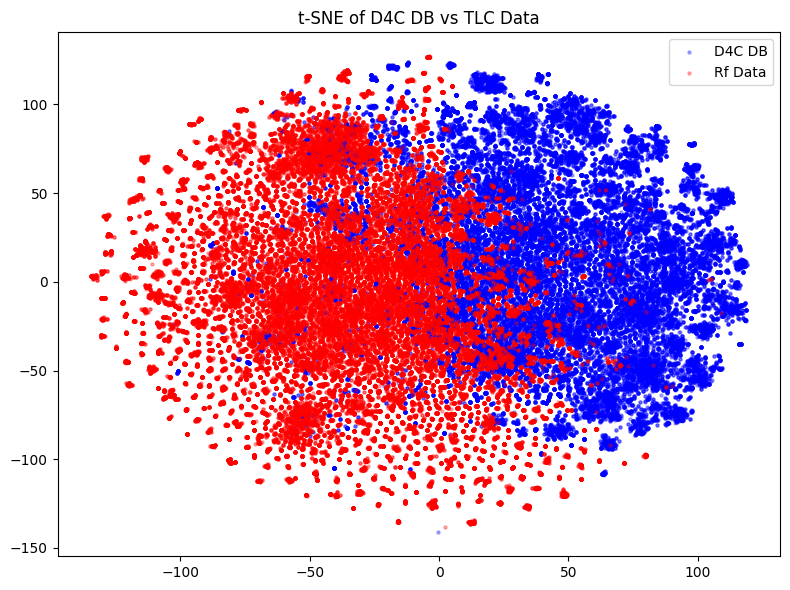

In [30]:
# T-sne
# 기존 D4C 데이터베이스와 비교
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from tqdm import tqdm

import sys
sys.path.append('../../../')
from functions import bring_DB
d4c_DB = bring_DB()
d4c_mol = d4c_DB['Chromophore_smiles'].drop_duplicates()

total = list(pd.concat([d4c_mol, united['Smiles']], axis=0, ignore_index = True))

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, countSimulation=True)
X = []
for smiles in tqdm(total):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        fp = generator.GetFingerprint(mol)
        arr = np.zeros((2048,), dtype=int)
        DataStructs.ConvertToNumpyArray(fp, arr)
        X.append(arr)
    else:
        continue


# t-SNE(2048 to 2)
# Check: t-SNE embedding and visualization
tsne = TSNE(n_components=2, random_state=1)
X_tsne = tsne.fit_transform(np.array(X))

# t-SNE Visualization
boundary = len(d4c_mol)
plt.figure(figsize=(8,6))
plt.scatter(X_tsne[:boundary, 0], X_tsne[:boundary, 1], c='blue', label='D4C DB', alpha=0.3, s=5)
plt.scatter(X_tsne[boundary:, 0], X_tsne[boundary:, 1], c='red', label='Rf Data', alpha=0.3, s=5)
plt.legend()
plt.title('t-SNE of D4C DB vs TLC Data')

plt.tight_layout()
plt.show()

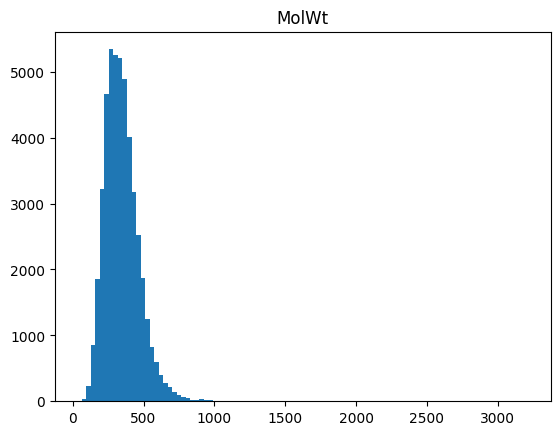

In [31]:
from rdkit.Chem import Descriptors

molwt_list = [Descriptors.MolWt(Chem.MolFromSmiles(smiles)) for smiles in pd.Series(united['Smiles']).drop_duplicates()]

import matplotlib.pyplot as plt
plt.hist(molwt_list, bins=100)
plt.title('MolWt')
plt.show()

In [32]:
from rdkit.Chem import Descriptors
import matplotlib.pyplot as plt

# PE -> Hexane으로 통일
converted_name =['EA',
 'Methanol',
 'Hexane',
 'DCM',
 'diethyl ether',
 'Toluene',
 'Chloroform',
 'Pentane',
 'Acetone',
 'Cyclohexane',
 'Benzene',
 'THF',
 np.nan]

# smiles 변환

elu_smiles = ['O=C(OCC)C', 'CO', 'CCCCCC', 'ClCCl', 'CCOCC', 'CC1=CC=CC=C1',
              'ClC(Cl)Cl', 'CCCCC', 'CC(C)=O', 'C1CCCCC1', 'C1=CC=CC=C1', 'C1CCOC1', None]

elu_smiles_convert = dict(zip(elu_smiles, converted_name))


elu1_name = [elu_smiles_convert[smiles] for smiles in raw['elu1_smiles']]
elu2_name = [elu_smiles_convert[smiles] for smiles in raw['elu2_smiles'] if pd.notna(smiles)]
elu_name = elu1_name + elu2_name 
elu1 = pd.Series(elu_name).value_counts()


plt.figure(figsize=(6,4))
plt.bar(elu1.index, list(elu1))
plt.title('eluents')
plt.xticks(fontsize = 10, rotation = 45)
plt.text(0.01, 0.7, 'PE -> Hexane', ha='left', va='top', transform=plt.gca().transAxes)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
plt.savefig('datahist2.png', bbox_inches='tight')
plt.show()

NameError: name 'raw' is not defined

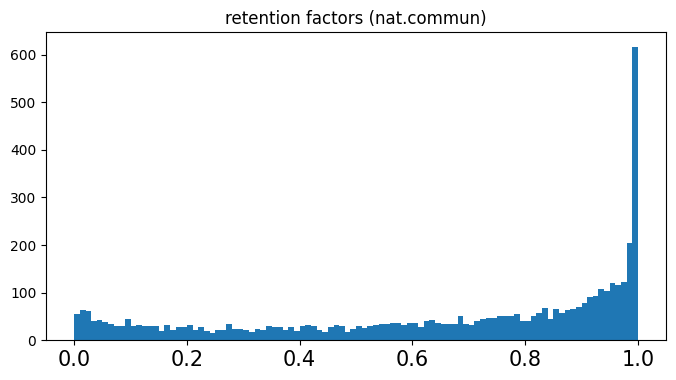

In [ ]:
raw_nat = pd.read_csv('./DB/collecting/primary_processed_PE_hex/nat_commun_raw_PE_hex.csv')
plt.figure(figsize=(8,4))
plt.hist(raw_nat['Rf'], bins=100)
plt.title('retention factors (nat.commun)')
plt.xticks(fontsize = 15)
plt.savefig('datahist3.png')
plt.show()

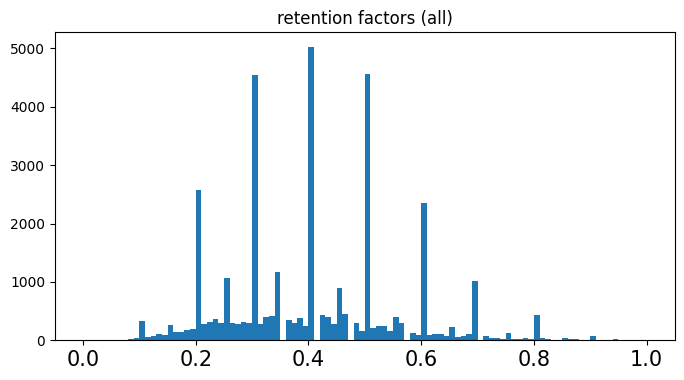

In [51]:
plt.figure(figsize=(8,4))
plt.hist(raw['Rf'], bins=100)
plt.title('retention factors (all)')
plt.xticks(fontsize = 15)
plt.savefig('datahist4.png')
plt.show()

In [ ]:
# compound - eluent pair

ce_pair = pd.Series([set(raw.iloc[i, :3].tolist()) for i in range(len(raw))], name='ce_pair_set')
raw_ce_pair = pd.concat([raw, ce_pair], axis=1)


In [ ]:
ce_pair_group = [raw_ce_pair[raw_ce_pair['ce_pair_set'] == set_] for set_ in raw_ce_pair['ce_pair_set'].drop_duplicates().tolist() 
                 if len(raw_ce_pair[raw_ce_pair['ce_pair_set']==set_])>1 ]

In [ ]:
elu12=pd.concat([raw_ce_pair['elu1_smiles'].drop_duplicates(), raw_ce_pair['elu2_smiles'].drop_duplicates()]).drop_duplicates().tolist()
# None은 polariyt_index = -1로 설정
polarity_index = [0.1, 2.8, 3.1, 4.4, 0.2, 0, 2.4, 5.1, 4.1, 5.1, 2.7, -1, 4.0]
elu12_polarity = dict(zip(elu12, polarity_index))

In [ ]:
# 항상 elu1이 더 높은 polarity를 가지도록 재정렬
groups = []
for a in range(len(ce_pair_group)):
    group = ce_pair_group[a]
    group.index = range(len(group))
    for i in range(len(group)):
        if elu12_polarity[group.loc[i,'elu1_smiles']] < elu12_polarity[group.loc[i,'elu2_smiles']]:
            elu_1, elu_2, ratio_1, ratio_2 = group.loc[i, 'elu1_smiles'], group.loc[i, 'elu2_smiles'], group.loc[i, 'ratio1'], group.loc[i, 'ratio2']
            group.loc[i, 'elu1_smiles'] = elu_2
            group.loc[i, 'elu2_smiles'] = elu_1
            group.loc[i, 'ratio1'] = ratio_2
            group.loc[i, 'ratio2'] = ratio_1
    
    group = group.sort_values(by=['ratio1'])
    groups.append(group)


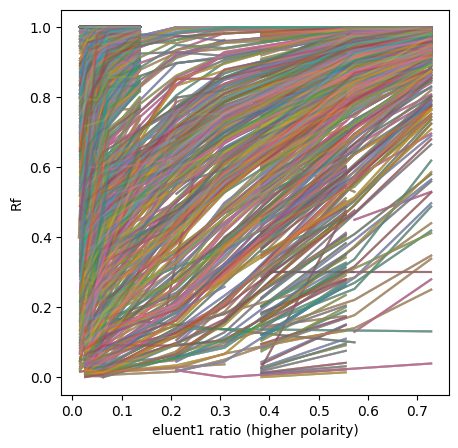

In [ ]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(5,5))
for i in range(6):
    for group in groups:
        x_line = group['ratio1']
        y_line = group['Rf']
        plt.plot(x_line, y_line, alpha=0.3)
        plt.xlabel('eluent1 ratio (higher polarity)')
        plt.ylabel('Rf')            
plt.show()

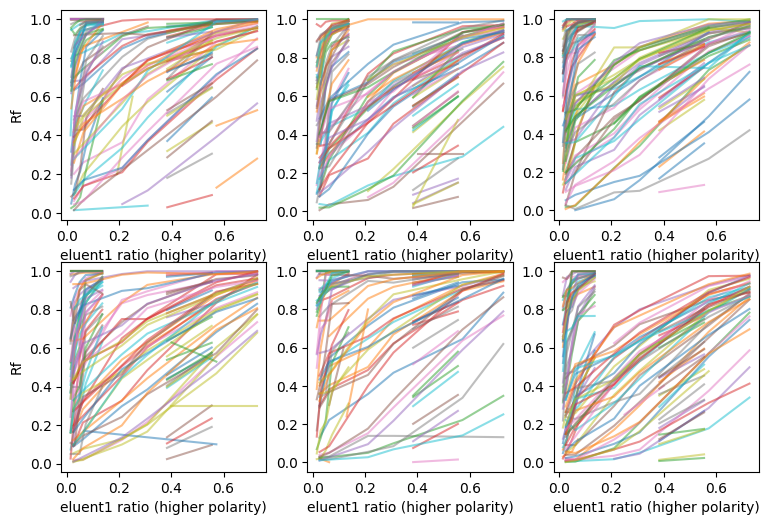

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2,3, figsize = (9,6))
for i in range(6):
    for idx, group in enumerate(groups[100*i:100*(i+1)]):
        x_line = group['ratio1']
        y_line = group['Rf']
        axs[i//3, i%3].plot(x_line, y_line, alpha=0.5)
        axs[i//3, i%3].set_xlabel('eluent1 ratio (higher polarity)')
        if i%3==0:
            axs[i//3, i%3].set_ylabel('Rf')            
        #axs[0].legend()
fig.show()

In [ ]:
# 지표들

#<H bonding>
# HBA, HBD

#<극성, 소수성>
# rdMolDescriptors.CalcTPSA  --> 극성 표면적
# Descriptors.MolLogP --> (octanol/water 분배계수. 높을수록 소수성, 낮을수록 극성)

#<vdW>
# rdMolDescriptors.CalcLabuteASA  --> Labute의 분자 접근 표면적 (vdW면적 포함됨)
# Descriptors.MolMR --> 몰 굴절률(전자 분극성)
# (vdW은 극성화도 비례하는데 극성화도는 분극성(전자 구름 크고 말랑)에 비례)

#<custom>
# TPSA/CalcLabuteASA (극성면적/전체면적 비율)
# TPSA - CalcLabteASA (비극성 면적)

# Rf값의 위 지표들 중 하나만의 함수로 표현되진 않을 것이므로, 최소한 compound는 eluent를 고정시키고, eluent는 compound를 고정시키고 봐야함. 


In [6]:
raw

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf
0,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,O=C(OCC)C,0.870508,0.129492,0.450000
1,BrCCCc1ccccc1,CCCCCC,CCOCC,0.445324,0.554676,0.979465
2,BrCCCc1ccccc1,CCCCCC,CCOCC,0.616228,0.383772,0.962609
3,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.691437,0.308563,0.983394
4,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.788794,0.211206,0.934233
...,...,...,...,...,...,...
9024,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.984422,0.015578,0.038870
9025,c1cnc2c(c1)ccc1cccnc12,ClCCl,None,1.000000,0.000000,0.029154
9026,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,CCCCCC,0.728082,0.271918,0.039532
9027,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,None,1.000000,0.000000,0.035176


In [6]:
# Snyder_solvent_polarity_selectivity_all

def solvent_snyder_convert(query_smiles, property):
    s= ['Hex', 'Cyclohexane', 'Carbon sulfide', 'Carbon tetrachloride', 'Isopropyl ether', 'Toluene', 'Chlorobenzene', 
    'Benzene', 'diethyl ether', 'Chloromethane', 'Dichloromethane', 'Tetrahydrofuran', '1,2-Dichloroethane', 'Ethyl methyl ketone', 
    'Acetone', 'Dioxane', 'EA', 'Dimethyl sulfoxide', 'Aniline', 'Nitromethane', 'Acetonitrile', 'Pyridine', '2-Propanol',
    'Ethanol' , 'Methanol', 'Ethylene glycol', 'Acetic acid', 'water']

    elu_list = ['EA', 'Methanol', 'PE', 'Hex', 'DCM', 'diethyl ether', 'Toluene', 'Chloroform', 'Pentane', 'Acetone', 'Cyclohexane', 'Benzene', 'THF', np.nan]
    elu_smiles = ['O=C(OCC)C', 'CO', 'CCCCCC', 'CCCCCC', 'ClCCl', 'CCOCC', 'CC1=CC=CC=C1', 'ClC(Cl)Cl', 'CCCCC', 'CC(C)=O', 'C1CCCCC1', 'C1=CC=CC=C1', 'C1CCOC1', None]
    elu_smiles_convert = dict(zip(elu_list, elu_smiles))

    s_smiles = np.array([elu_smiles_convert[name] if name in elu_list else None for name in s])

    P = [0.1, 0.2, 0.3, 1.6, 2.4, 2.4, 2.7, 2.7, 2.8, 4.1, 3.1, 4.0, 3.5, 4.7, 5.1, 4.8, 4.4, 7.2, 6.3, 6.0, 5.8, 5.3, 3.9, 4.3, 5.1, 6.9, 6.0, 10.2]
    x_e = [0, 0, 0, 0, 0.48, 0.25, 0.23, 0.23, 0.53, 0.25, 0.29, 0.38, 0.30, 0.35, 0.35, 0.36, 0.34, 0.39, 0.32, 0.28, 0.31, 0.41, 0.55, 0.52, 0.48, 0.43, 0.39, 0.37]
    x_d = [0, 0, 0, 0, 0.14, 0.28, 0.33, 0.32, 0.13, 0.41, 0.18, 0.20, 0.21, 0.22, 0.23, 0.24, 0.23, 0.23, 0.32, 0.31, 0.27, 0.22, 0.19, 0.19, 0.22, 0.29, 0.31, 0.37]
    x_n = [0, 0, 0, 0, 0.38, 0.47, 0.44, 0.45, 0.34, 0.33, 0.53, 0.42, 0.49, 0.43, 0.42, 0.40, 0.43, 0.39, 0.36, 0.40, 0.42, 0.36, 0.27, 0.29, 0.31, 0.28, 0.30, 0.25]

    # Check if query_smiles is present in s_smiles, and return the corresponding value or None
    idx = np.where(s_smiles == query_smiles)[0]
    if len(idx) == 0:
        out = None
    else:
        idx = idx[0]
        if property == 'p':
            out = P[idx]
        elif property == 's1':
            out = x_e[idx]
        elif property == 's2':
            out = x_d[idx]
        elif property == 's3':
            out = x_n[idx]
        else:
            out = None

    return out

In [54]:
aa=np.array([4,4,67,8,1,4,6,78])
np.where(aa==1)[0][0]

4

In [46]:
# compound특성에 대해 plot (동일 eluent)

In [ ]:
def make_extended_raw_snyder(raw_Df, column):
    def safe_mol(smiles):
        return Chem.MolFromSmiles(smiles) if isinstance(smiles, str) and smiles.strip() else None

    extend1 = pd.DataFrame({
        'HBD': [CalcNumHBD(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'HBA': [CalcNumHBA(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'CalcTPSA': [rdMolDescriptors.CalcTPSA(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'MolLogP': [Descriptors.MolLogP(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'CalcLabuteASA': [rdMolDescriptors.CalcLabuteASA(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'MolMR': [Descriptors.MolMR(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]]
    })

    extend2 = pd.DataFrame({
        'TPSA_ratio': extend1.apply(
            lambda row: row['CalcTPSA'] / row['CalcLabuteASA']
            if row['CalcTPSA'] is not None and row['CalcLabuteASA'] not in (None, 0)
            else None, axis=1),
        'HBA+HBD': extend1.apply(
            lambda row: row['HBD'] + row['HBA']
            if row['HBD'] is not None and row['HBA'] is not None
            else None, axis=1)
    })

    extend_snyder = pd.DataFrame({
        'polaraity_index' : [solvent_snyder_convert(smiles, 'p') for smiles in raw_Df[column]],
        's1' : [solvent_snyder_convert(smiles, 's1') for smiles in raw_Df[column]],
        's2' : [solvent_snyder_convert(smiles, 's2') for smiles in raw_Df[column]],
        's3' : [solvent_snyder_convert(smiles, 's3') for smiles in raw_Df[column]]
    })

    raw_extended = pd.concat([raw_Df, extend1, extend2, extend_snyder], axis=1)
    return raw_extended

In [3]:
def make_extended_raw(raw_Df, column):
    def safe_mol(smiles):
        return Chem.MolFromSmiles(smiles) if isinstance(smiles, str) and smiles.strip() else None

    extend = pd.DataFrame({
        'HBD': [CalcNumHBD(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'HBA': [CalcNumHBA(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'CalcTPSA': [rdMolDescriptors.CalcTPSA(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'MolLogP': [Descriptors.MolLogP(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'CalcLabuteASA': [rdMolDescriptors.CalcLabuteASA(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]],
        'MolMR': [Descriptors.MolMR(safe_mol(smiles)) if safe_mol(smiles) else None for smiles in raw_Df[column]]
    })

    extend2 = pd.DataFrame({
        'TPSA_ratio': extend.apply(
            lambda row: row['CalcTPSA'] / row['CalcLabuteASA']
            if row['CalcTPSA'] is not None and row['CalcLabuteASA'] not in (None, 0)
            else None, axis=1),
        'HBA+HBD': extend.apply(
            lambda row: row['HBD'] + row['HBA']
            if row['HBD'] is not None and row['HBA'] is not None
            else None, axis=1)
    })

    extend1 =  extend.iloc[:,:3]
    extend3 = extend.iloc[:, 3:]

    raw_extended = pd.concat([raw_Df, extend1, extend2, extend3], axis=1)
    return raw_extended

In [ ]:
raw_compound_extended = make_extended_raw(raw, 'Smiles')

reverse_ratio_idx = raw_compound_extended[raw_compound_extended['ratio1']<raw_compound_extended['ratio2']].index
for i in reverse_ratio_idx:
    ratio1 = raw_compound_extended.loc[i,'ratio1']
    ratio2 = raw_compound_extended.loc[i,'ratio2']
    raw_compound_extended.loc[i,'ratio1'] = ratio2
    raw_compound_extended.loc[i,'ratio2'] = ratio1


In [ ]:
er_list = ['_'.join(map(str,raw_compound_extended.iloc[i,1:5])) for i in range(len(raw_compound_extended))]
raw_compound_extended['er_list'] = er_list

In [ ]:
raw_compound_extended

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,HBD,HBA,CalcTPSA,MolLogP,CalcLabuteASA,MolMR,TPSA_ratio,HBA+HBD,er_list
0,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,O=C(OCC)C,0.870508,0.129492,0.450000,1,1,12.36,3.2824,82.684819,59.196,0.149483,2.0,CCCCCC_O=C(OCC)C_0.8705081641293182_0.12949183...
1,BrCCCc1ccccc1,CCCCCC,CCOCC,0.554676,0.445324,0.979465,0,0,0.00,3.0141,70.393777,48.557,0.000000,0.0,CCCCCC_CCOCC_0.5546756788357236_0.445324321164...
2,BrCCCc1ccccc1,CCCCCC,CCOCC,0.616228,0.383772,0.962609,0,0,0.00,3.0141,70.393777,48.557,0.000000,0.0,CCCCCC_CCOCC_0.6162278887833084_0.383772111216...
3,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.691437,0.308563,0.983394,0,0,0.00,3.0141,70.393777,48.557,0.000000,0.0,CCCCCC_O=C(OCC)C_0.6914372153256559_0.30856278...
4,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.788794,0.211206,0.934233,0,0,0.00,3.0141,70.393777,48.557,0.000000,0.0,CCCCCC_O=C(OCC)C_0.7887938335683486_0.21120616...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9024,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.984422,0.015578,0.038870,0,2,25.78,2.7830,81.234028,57.044,0.317355,2.0,ClCCl_CO_0.9844224412537776_0.015577558746222327
9025,c1cnc2c(c1)ccc1cccnc12,ClCCl,None,1.000000,0.000000,0.029154,0,2,25.78,2.7830,81.234028,57.044,0.317355,2.0,ClCCl_None_1.0_0.0
9026,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,CCCCCC,0.728082,0.271918,0.039532,0,2,25.78,2.7830,81.234028,57.044,0.317355,2.0,O=C(OCC)C_CCCCCC_0.7280821636863829_0.27191783...
9027,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,None,1.000000,0.000000,0.035176,0,2,25.78,2.7830,81.234028,57.044,0.317355,2.0,O=C(OCC)C_None_1.0_0.0


In [ ]:
value_count_er = raw_compound_extended['er_list'].drop_duplicates()
value_count_er.index = range(len(value_count_er))
er_group_list = [raw_compound_extended[raw_compound_extended['er_list']==er] for er in value_count_er]

/tmp/ipykernel_3258820/1214481017.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  group_df.sort_values(by=column_name, inplace=True)


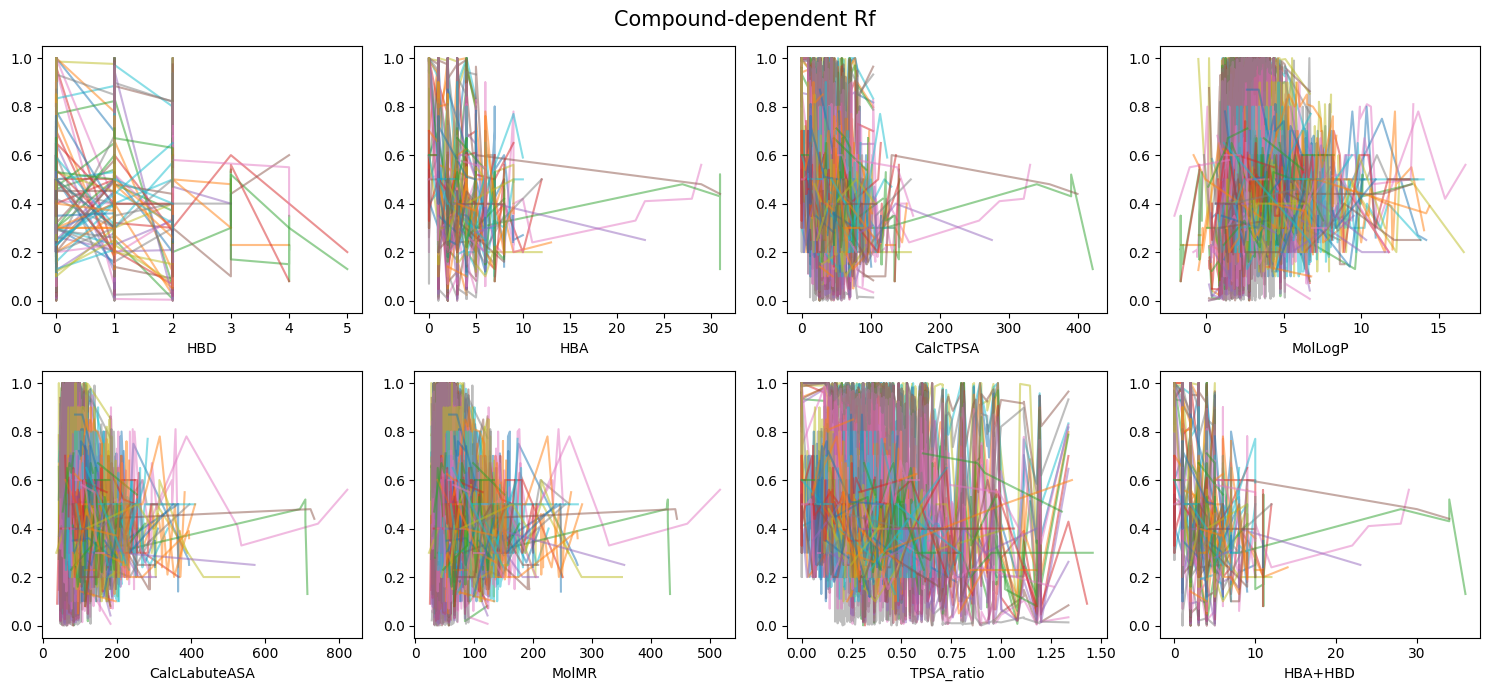

In [ ]:
fig, axs = plt.subplots(2,4, figsize = (15,7))

for idx, column_name in enumerate(raw_compound_extended.columns[6:-1]):
    for group_df in er_group_list:
        group_df.sort_values(by=column_name, inplace=True)
        x_line = group_df[column_name]
        y_line = group_df['Rf']
        axs[idx//4, idx%4].plot(x_line, y_line, alpha=0.5)
        axs[idx//4, idx%4].set_xlabel(column_name)
# This line is incorrect. The correct way to set a title for a matplotlib Figure is:
fig.suptitle('Compound-dependent Rf', fontsize=15)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
plt.savefig('data_analysis.png',dpi=400, bbox_inches='tight')
plt.show()

In [ ]:
# eluent특성에 대해 plot (동일 compound)

In [23]:
raw_eluent1 = make_extended_raw(raw, 'elu1_smiles').iloc[:,6:].fillna(0).multiply(raw['ratio1'], axis=0)
raw_eluent2 = make_extended_raw(raw, 'elu2_smiles').iloc[:,6:].fillna(0).multiply(raw['ratio2'], axis=0)
raw_eluent_extended = pd.concat([raw, (raw_eluent1+raw_eluent2)], axis=1)

In [24]:
compound_counts = raw_eluent_extended['Smiles'].value_counts()
multi_compounds = compound_counts[compound_counts > 1].index
compound_group_list = [group for name, group in raw_eluent_extended.groupby('Smiles') if name in multi_compounds]

In [25]:
raw_eluent_extended

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,HBD,HBA,CalcTPSA,MolLogP,CalcLabuteASA,MolMR,TPSA_ratio,HBA+HBD,polaraity_index,s1,s2,s3
0,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,O=C(OCC)C,0.870508,0.129492,0.450000,0.000000,0.258984,3.405635,2.325389,40.116591,28.843646,0.091773,0.258984,0.656815,0.044027,0.029783,0.055681
1,BrCCCc1ccccc1,CCCCCC,CCOCC,0.445324,0.554676,0.979465,0.000000,0.554676,5.119657,1.730292,36.339364,25.573286,0.155388,0.554676,1.597624,0.293978,0.072108,0.188590
2,BrCCCc1ccccc1,CCCCCC,CCOCC,0.616228,0.383772,0.962609,0.000000,0.383772,3.542217,1.994133,37.641023,26.880527,0.107511,0.383772,1.136185,0.203399,0.049890,0.130483
3,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.691437,0.308563,0.983394,0.000000,0.617126,8.115201,1.964167,39.497934,27.499002,0.218685,0.617126,1.426820,0.104911,0.070969,0.132682
4,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.788794,0.211206,0.934233,0.000000,0.422412,5.554722,2.160555,39.834283,28.230053,0.149686,0.422412,1.008187,0.071810,0.048577,0.090819
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9024,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.984422,0.015578,0.038870,0.015578,0.015578,0.315134,1.393258,29.099466,16.441678,0.023286,0.031155,0.079446,0.007477,0.003427,0.004829
9025,c1cnc2c(c1)ccc1cccnc12,ClCCl,None,1.000000,0.000000,0.029154,0.000000,0.000000,0.000000,1.421500,29.345783,16.573000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9026,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,CCCCCC,0.728082,0.271918,0.039532,0.000000,1.456164,19.148561,1.117913,38.048571,24.348831,0.516007,1.456164,3.230753,0.247548,0.167459,0.313075
9027,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,None,1.000000,0.000000,0.035176,0.000000,2.000000,26.300000,0.569400,37.109145,22.307000,0.708720,2.000000,4.400000,0.340000,0.230000,0.430000


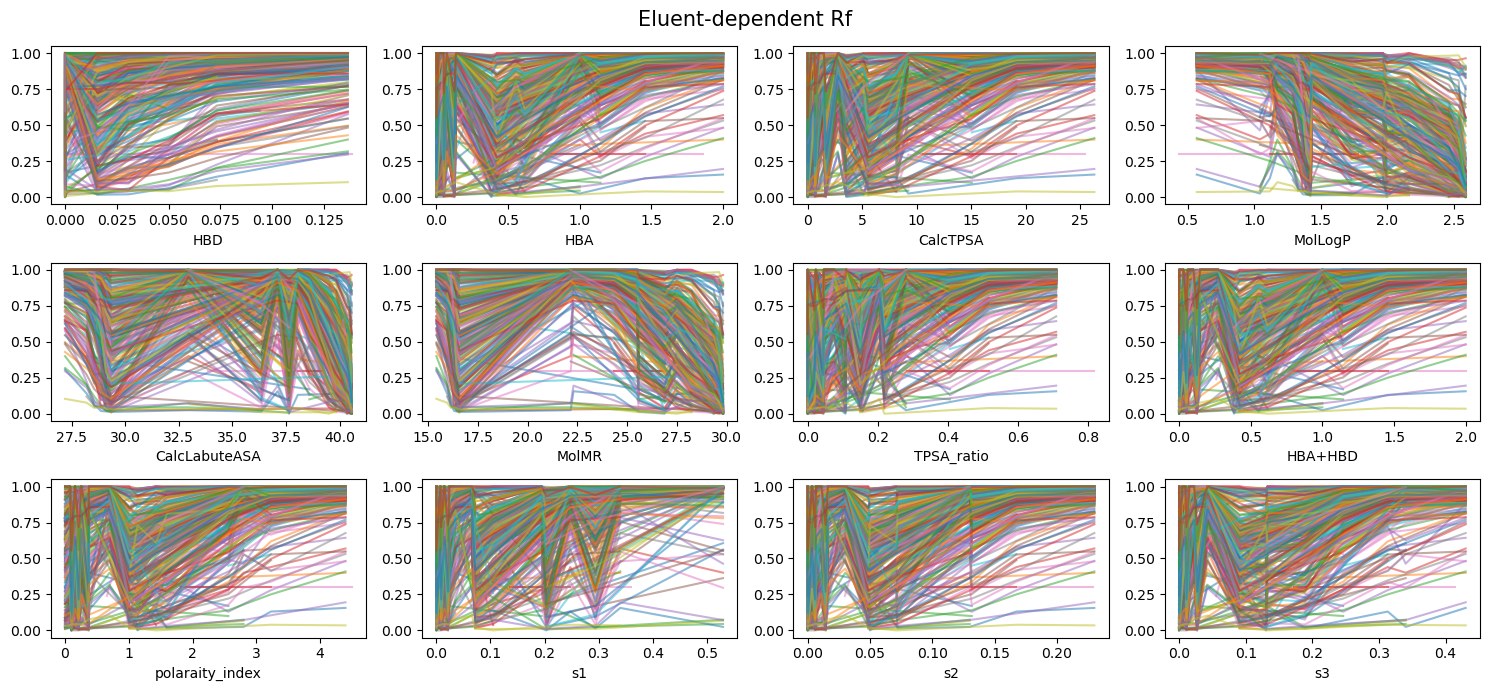

In [65]:
import matplotlib.pyplot as plt
fig,axs = plt.subplots(3,4, figsize = (15,7))

for idx,column_name in enumerate(raw_eluent_extended.columns[6:]):
    for group in compound_group_list:
        group.sort_values(by = column_name, inplace = True)
        x_line = group[column_name]
        y_line = group['Rf']
        axs[idx//4, idx%4].plot(x_line, y_line, alpha=0.5)
        axs[idx//4, idx%4].set_xlabel(column_name)
plt.suptitle('Eluent-dependent Rf', fontsize=15)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
#plt.savefig('data_analysis2.png', dpi=400, bbox_inches='tight')
plt.show()



In [ ]:
# eluent특성에 대해 plot (동일 compound, 동일 eluent 조합 but 비율만 변화)

In [26]:
raw_eluent_extended

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,HBD,HBA,CalcTPSA,MolLogP,CalcLabuteASA,MolMR,TPSA_ratio,HBA+HBD,polaraity_index,s1,s2,s3
0,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,O=C(OCC)C,0.870508,0.129492,0.450000,0.000000,0.258984,3.405635,2.325389,40.116591,28.843646,0.091773,0.258984,0.656815,0.044027,0.029783,0.055681
1,BrCCCc1ccccc1,CCCCCC,CCOCC,0.445324,0.554676,0.979465,0.000000,0.554676,5.119657,1.730292,36.339364,25.573286,0.155388,0.554676,1.597624,0.293978,0.072108,0.188590
2,BrCCCc1ccccc1,CCCCCC,CCOCC,0.616228,0.383772,0.962609,0.000000,0.383772,3.542217,1.994133,37.641023,26.880527,0.107511,0.383772,1.136185,0.203399,0.049890,0.130483
3,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.691437,0.308563,0.983394,0.000000,0.617126,8.115201,1.964167,39.497934,27.499002,0.218685,0.617126,1.426820,0.104911,0.070969,0.132682
4,BrCCCc1ccccc1,CCCCCC,O=C(OCC)C,0.788794,0.211206,0.934233,0.000000,0.422412,5.554722,2.160555,39.834283,28.230053,0.149686,0.422412,1.008187,0.071810,0.048577,0.090819
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9024,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.984422,0.015578,0.038870,0.015578,0.015578,0.315134,1.393258,29.099466,16.441678,0.023286,0.031155,0.079446,0.007477,0.003427,0.004829
9025,c1cnc2c(c1)ccc1cccnc12,ClCCl,None,1.000000,0.000000,0.029154,0.000000,0.000000,0.000000,1.421500,29.345783,16.573000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9026,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,CCCCCC,0.728082,0.271918,0.039532,0.000000,1.456164,19.148561,1.117913,38.048571,24.348831,0.516007,1.456164,3.230753,0.247548,0.167459,0.313075
9027,c1cnc2c(c1)ccc1cccnc12,O=C(OCC)C,None,1.000000,0.000000,0.035176,0.000000,2.000000,26.300000,0.569400,37.109145,22.307000,0.708720,2.000000,4.400000,0.340000,0.230000,0.430000


In [27]:
ce_pair = pd.Series(['_'.join(map(str,raw_eluent_extended.iloc[i, :3])) for i in range(len(raw_eluent_extended))], name='ce_pair_set')
raw_eluent_extended_ce_pair = pd.concat([raw_eluent_extended, ce_pair], axis=1)

unique_ce_pair = ce_pair.value_counts()
ce_pair_use = unique_ce_pair[unique_ce_pair>1].index
pair_group_list = [pair_group for name, pair_group in raw_eluent_extended_ce_pair.groupby('ce_pair_set') if name in ce_pair_use]


In [55]:
import numpy as np
g1 = [np.var(g['Rf']) for g in pair_group_list if len(g) >5]
#g_ = [g['Rf'] for g in pair_group_list if len(g) > 4]
g2 = [g['ratio1'] for g in pair_group_list if len(g) >5]
print(g1)


[0.03884450991380555, 0.03755226138533333, 0.06118141884413889]


In [53]:
gg=[g for g in pair_group_list if len(g) <3]

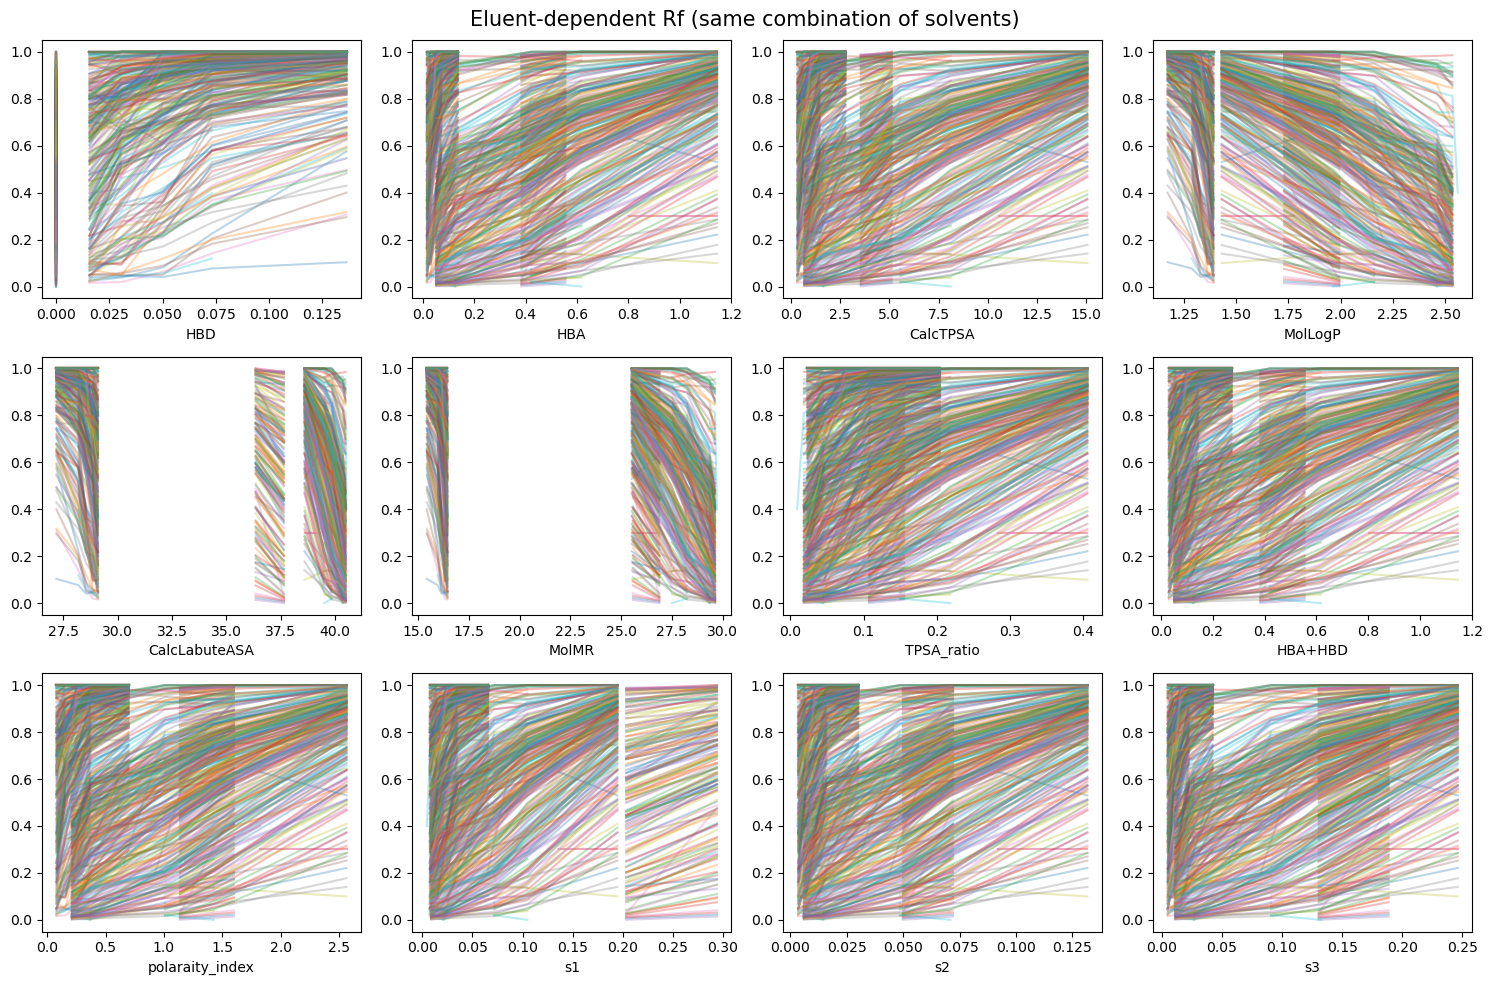

In [71]:
fig,axs = plt.subplots(3,4, figsize = (15,10))

for idx,column_name in enumerate(raw_eluent_extended.columns[6:]):
    for group in pair_group_list:
        group.sort_values(by = column_name)
        x_line = group[column_name]
        y_line = group['Rf']
        axs[idx//4, idx%4].plot(x_line, y_line, alpha=0.3)
        axs[idx//4, idx%4].set_xlabel(column_name)
plt.suptitle('Eluent-dependent Rf (same combination of solvents)', fontsize=15)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
#plt.savefig('data_analysis3.png', dpi=400, bbox_inches='tight')
plt.show()


In [ ]:
# 예측된 valid set이 경향성 (동일 compound, 동일 용매 조합, 용매 비율 변화화)

In [ ]:
valid_pred = pd.read_csv('./predicted_values/valid_pred.csv')
valid_pred.columns = ['prediction']
valid_DB = pd.read_csv('./DB/Rf/raw_DB_valid.csv')
valid_set = pd.concat([valid_DB, valid_pred], axis=1)


In [ ]:
valid_eluent1 = make_extended_raw(valid_set, 'elu1_smiles').iloc[:,7:].fillna(0).multiply(valid_set['ratio1'], axis=0)
valid_eluent2 = make_extended_raw(valid_set, 'elu2_smiles').iloc[:,7:].fillna(0).multiply(valid_set['ratio2'], axis=0)
valid_eluent_extended = pd.concat([valid_set, (valid_eluent1+valid_eluent2)], axis=1)

In [ ]:
valid_ce_pair = pd.Series(['_'.join(map(str,valid_eluent_extended.iloc[i, :3])) for i in range(len(valid_eluent_extended))], name='ce_pair_set')
valid_eluent_extended_ce_pair = pd.concat([valid_eluent_extended, valid_ce_pair], axis=1)

valid_unique_ce_pair = valid_ce_pair.value_counts()
valid_ce_pair_use = valid_unique_ce_pair[valid_unique_ce_pair>1].index
pair_group_list = [pair_group for name, pair_group in valid_eluent_extended_ce_pair.groupby('ce_pair_set') if name in valid_ce_pair_use]


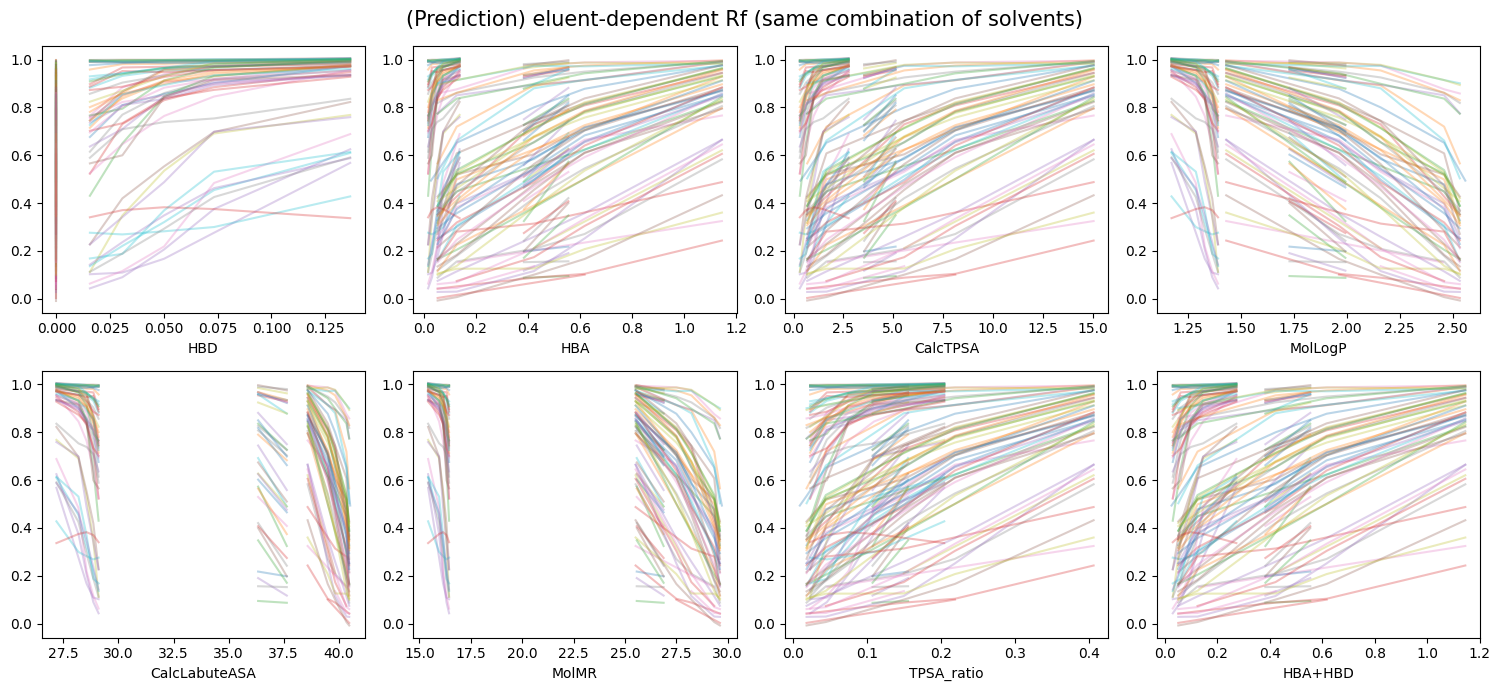

In [ ]:
import matplotlib.pyplot as plt
fig,axs = plt.subplots(2,4, figsize = (15,7))

for idx,column_name in enumerate(valid_eluent_extended.columns[7:]):
    for group in pair_group_list:
        group.sort_values(by = column_name)
        x_line = group[column_name]
        y_line = group['prediction']
        axs[idx//4, idx%4].plot(x_line, y_line, alpha=0.3)
        axs[idx//4, idx%4].set_xlabel(column_name)
plt.suptitle('(Prediction) eluent-dependent Rf (same combination of solvents)', fontsize=15)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
plt.savefig('(prediction)data_analysis3.png', dpi=400, bbox_inches='tight')
plt.show()

In [ ]:
# valid set 에러 큰 애들만 경향서 추적

0.6634220200000001


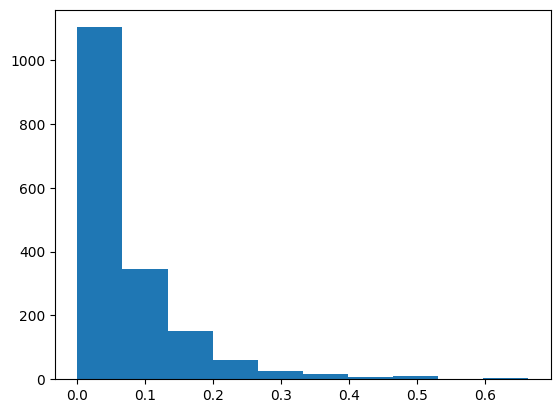

In [ ]:
valid_error = abs(valid_eluent_extended['Rf'] - valid_eluent_extended['prediction'])
print(max(valid_error))
plt.hist(valid_error)
plt.show()

In [ ]:
valid_error.name = 'error'
valid_eluent_extended_error = pd.concat([valid_eluent_extended, valid_error], axis=1)
valid_eluent_extended_error

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,prediction,HBD,HBA,CalcTPSA,MolLogP,CalcLabuteASA,MolMR,TPSA_ratio,HBA+HBD,error
0,BrCc1cccc(CBr)c1,CCCCCC,CCOCC,0.445324,0.554676,0.892575,0.967242,0.0,0.554676,5.119657,1.730292,36.339364,25.573286,0.155388,0.554676,0.074667
1,BrCc1cccc(CBr)c1,CCCCCC,CCOCC,0.616228,0.383772,0.830672,0.922832,0.0,0.383772,3.542217,1.994133,37.641023,26.880527,0.107511,0.383772,0.092160
2,BrCc1cccc(CBr)c1,CCCCCC,O=C(OCC)C,0.427572,0.572428,0.995327,0.988883,0.0,1.144856,15.054863,1.431898,38.586327,25.517636,0.405691,1.144856,0.006444
3,BrCc1cccc(CBr)c1,CCCCCC,O=C(OCC)C,0.691437,0.308563,0.899026,0.913405,0.0,0.617126,8.115201,1.964167,39.497934,27.499002,0.218685,0.617126,0.014379
4,BrCc1cccc(CBr)c1,CCCCCC,O=C(OCC)C,0.788794,0.211206,0.805533,0.891882,0.0,0.422412,5.554722,2.160555,39.834283,28.230053,0.149686,0.422412,0.086349
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1714,c1ccc2c(c1)CCOC2n1nnc2ccccc21,CCCCCC,O=C(OCC)C,0.749234,0.250766,0.300000,0.722940,0.0,0.501533,6.595156,2.080754,39.697610,27.932995,0.177723,0.501533,0.422940
1715,c1ccc2cc(N3CCCCC3)ccc2c1,CCCCCC,O=C(OCC)C,0.934176,0.065824,0.500000,0.595888,0.0,0.131649,1.731182,2.453819,40.336550,29.321725,0.046651,0.131649,0.095888
1716,c1ccc2ccccc2c1,CCCCCC,O=C(OCC)C,0.986789,0.013211,0.700000,0.554357,0.0,0.026422,0.347450,2.559951,40.518320,29.716798,0.009363,0.026422,0.145643
1717,c1ccc2nc(C3CCCCC3)cnc2c1,CCCCCC,O=C(OCC)C,0.934176,0.065824,0.380000,0.371036,0.0,0.131649,1.731182,2.453819,40.336550,29.321725,0.046651,0.131649,0.008964


In [ ]:
valid_ce_pair = pd.Series(['_'.join(map(str,valid_eluent_extended_error.iloc[i, :3])) for i in range(len(valid_eluent_extended_error))], name='ce_pair_set')
valid_eluent_extended_ce_pair = pd.concat([valid_eluent_extended_error, valid_ce_pair], axis=1)

valid_unique_ce_pair = valid_ce_pair.value_counts()
valid_ce_pair_use = valid_unique_ce_pair[valid_unique_ce_pair>1].index
pair_group_list = [pair_group for name, pair_group in valid_eluent_extended_ce_pair.groupby('ce_pair_set') if name in valid_ce_pair_use]

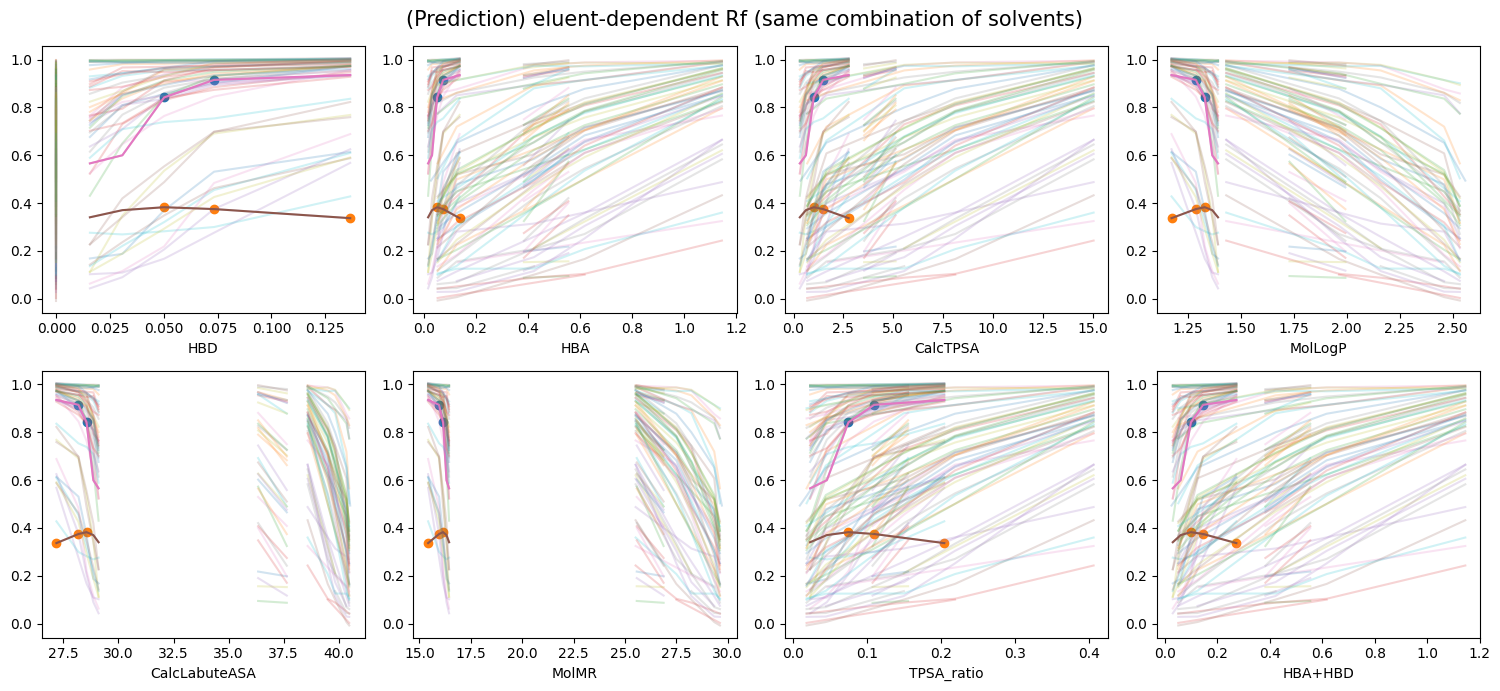

In [ ]:
import matplotlib.pyplot as plt
fig,axs = plt.subplots(2,4, figsize = (15,7))

for idx,column_name in enumerate(valid_eluent_extended_error.columns[7:-1]):
    for group in pair_group_list:
        group.sort_values(by = column_name)
        x_line = group[column_name]
        y_line = group['prediction']
        axs[idx//4, idx%4].plot(x_line, y_line, alpha=0.2)
        axs[idx//4, idx%4].set_xlabel(column_name)
        group_out = group[group['error']>=0.5]
        if not group_out.empty:
            import random
            import matplotlib


            x_line_out = group[column_name]
            y_line_out = group['prediction']
            x_out = group_out[column_name]
            y_out = group_out['prediction']
            axs[idx//4, idx%4].plot(x_line_out, y_line_out)
            axs[idx//4, idx%4].scatter(x_out, y_out)



plt.suptitle('(Prediction) eluent-dependent Rf (same combination of solvents)', fontsize=15)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
#plt.savefig('(prediction_error)data_analysis_0.5.png', dpi=400, bbox_inches='tight')
plt.show()

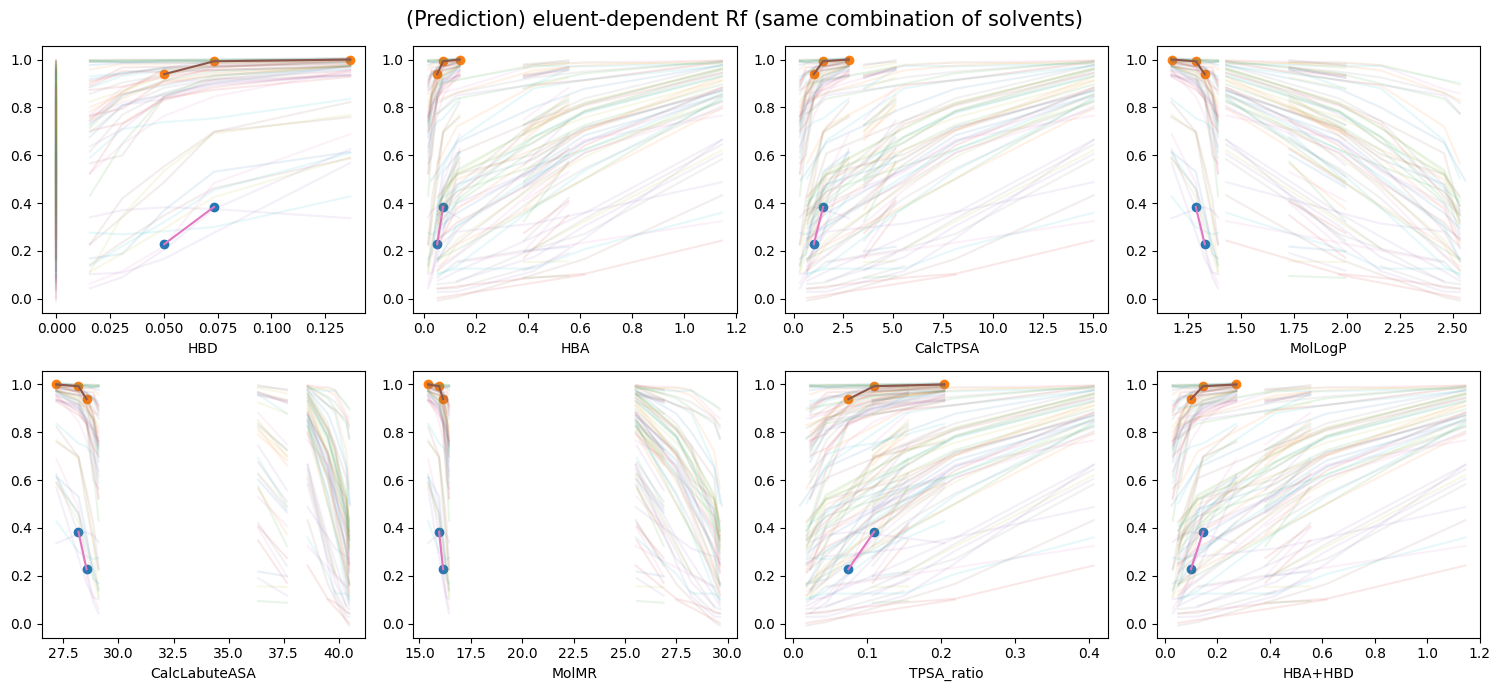

In [ ]:
# 위 plot에 있는 데이터들의 실제 label이 경향을 따르는 지 체크

import matplotlib.pyplot as plt
fig,axs = plt.subplots(2,4, figsize = (15,7))

for idx,column_name in enumerate(valid_eluent_extended_error.columns[7:-1]):
    for group in pair_group_list:
        group.sort_values(by = column_name)
        x_line = group[column_name]
        y_line = group['prediction']
        axs[idx//4, idx%4].plot(x_line, y_line, alpha=0.1)
        group_out = group[group['error']>=0.5]
        if not group_out.empty:
            x_line_label = group_out[column_name]
            y_line_label = group_out['Rf']
            x_out = group_out[column_name]
            y_out = group_out['Rf']
            color = 'tab:orange'
            axs[idx//4, idx%4].plot(x_line_label, y_line_label)
            axs[idx//4, idx%4].scatter(x_out, y_out)
            axs[idx//4, idx%4].set_xlabel(column_name)


plt.suptitle(' eluent-dependent Rf (same combination of solvents)', fontsize=15)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
plt.savefig('(label)data_analysis_0.5.png', dpi=400, bbox_inches='tight')
plt.show()

In [ ]:
error_extended_sort = valid_eluent_extended_error.sort_values(by='error', ascending=False)


In [ ]:
error_compound_df = error_extended_sort[error_extended_sort['error']>0.6]
error_compound = list(error_compound_df['Smiles'].drop_duplicates())

In [ ]:
error_compound_df

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,prediction,HBD,HBA,CalcTPSA,MolLogP,CalcLabuteASA,MolMR,TPSA_ratio,HBA+HBD,error
1615,O=S(=O)(CS(=O)(=O)c1ccccc1)c1ccccc1,ClCCl,CO,0.863379,0.136621,1.000000,0.336578,0.136621,0.136621,2.763848,1.173806,27.185487,15.421255,0.204223,0.273243,0.663422
1616,O=S(=O)(CS(=O)(=O)c1ccccc1)c1ccccc1,ClCCl,CO,0.926681,0.073319,0.992785,0.374607,0.073319,0.073319,1.483246,1.288572,28.186440,15.954905,0.109598,0.146638,0.618178
1361,Nc1ccc(Cl)cc1O,ClCCl,CO,0.949896,0.050104,0.227645,0.841623,0.050104,0.050104,1.013602,1.330662,28.553526,16.150614,0.074896,0.100208,0.613978


In [ ]:
from rdkit.Chem.Draw import MolsToGridImage

mols = [Chem.MolFromSmiles(error_compound[i]) for i in range(len(error_compound))]
MolsToGridImage(mols, molsPerRow = 2, subImgSize = (600,600))

In [16]:
pd.read_csv('./predicted_values/only_nat_physics_check_model_5s_8penalty.csv')

,0
0,0.268871
1,0.291387
2,0.357398
3,0.434876
4,0.435138
...,...
4714,0.435888
4715,0.436643
4716,0.433885
4717,0.434449


In [21]:
# only_D4C 학습 모델 ---예측---> only_nat 데이터
# 예측한 데이터들의 실제 이 경향을 따르는 지 체크

only_nat_physics_pred = pd.read_csv('./predicted_values/only_nat_physics_check_model_5s_8penalty.csv')
only_nat_physics_pred.columns = ['prediction']
valid_DB = pd.read_csv('./DB/Rf/only_nat_raw_DB.csv')

valid_DB = valid_DB.iloc[:, :-8]
valid_set = pd.concat([valid_DB, only_nat_physics_pred], axis=1)

valid_eluent1 = make_extended_raw(valid_set, 'elu1_smiles').iloc[:,7:].fillna(0).multiply(valid_set['ratio1'], axis=0)
valid_eluent2 = make_extended_raw(valid_set, 'elu2_smiles').iloc[:,7:].fillna(0).multiply(valid_set['ratio2'], axis=0)
valid_eluent_extended = pd.concat([valid_set, (valid_eluent1+valid_eluent2)], axis=1)

valid_ce_pair = pd.Series(['_'.join(map(str,valid_eluent_extended.iloc[i, :3])) for i in range(len(valid_eluent_extended))], name='ce_pair_set')
valid_eluent_extended_ce_pair = pd.concat([valid_eluent_extended, valid_ce_pair], axis=1)

valid_unique_ce_pair = valid_ce_pair.value_counts()
valid_ce_pair_use = valid_unique_ce_pair[valid_unique_ce_pair>1].index
pair_group_list = [pair_group for name, pair_group in valid_eluent_extended_ce_pair.groupby('ce_pair_set') if name in valid_ce_pair_use]


In [18]:
valid_eluent_extended

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,prediction,HBD,HBA,CalcTPSA,TPSA_ratio,HBA+HBD,MolLogP,CalcLabuteASA,MolMR
0,O=C(CCCl)c1ccccc1,CCCCCC,NaN,1.000000,0.000000,0.049175,0.268871,0.0,0.000000,0.000000,0.000000,0.000000,2.586600,40.563962,29.816000
1,O=C(CCCl)c1ccccc1,CCCCCC,O=C(OCC)C,0.973922,0.026078,0.262708,0.291387,0.0,0.052155,0.685844,0.018482,0.052155,2.533996,40.473868,29.620182
2,O=C(CCCl)c1ccccc1,CCCCCC,O=C(OCC)C,0.937260,0.062740,0.410200,0.357398,0.0,0.125479,1.650052,0.044465,0.125479,2.460042,40.347208,29.344888
3,O=C(CCCl)c1ccccc1,CCCCCC,O=C(OCC)C,0.788794,0.211206,0.719773,0.434876,0.0,0.422412,5.554722,0.149686,0.422412,2.160555,39.834283,28.230053
4,O=C(CCCl)c1ccccc1,CCCCCC,O=C(OCC)C,0.691437,0.308563,0.794856,0.435138,0.0,0.617126,8.115201,0.218685,0.617126,1.964167,39.497934,27.499002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4714,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.616228,0.383772,0.498683,0.435888,0.0,0.383772,3.542217,0.107511,0.383772,1.994133,37.641023,26.880527
4715,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.445324,0.554676,0.662423,0.436643,0.0,0.554676,5.119657,0.155388,0.554676,1.730292,36.339364,25.573286
4716,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,0.433885,0.0,1.000000,9.230000,0.280142,1.000000,1.042800,32.947623,22.167000
4717,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.445324,0.554676,0.010664,0.434449,0.0,0.554676,5.119657,0.155388,0.554676,1.730292,36.339364,25.573286


In [19]:
pair_group_list[12]

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,prediction,HBD,HBA,CalcTPSA,TPSA_ratio,HBA+HBD,MolLogP,CalcLabuteASA,MolMR,ce_pair_set
4190,BrCc1ccccc1I,CCCCCC,CCOCC,0.445324,0.554676,0.958931,0.436484,0.0,0.554676,5.119657,0.155388,0.554676,1.730292,36.339364,25.573286,BrCc1ccccc1I_CCCCCC_CCOCC
4191,BrCc1ccccc1I,CCCCCC,CCOCC,0.616228,0.383772,0.906100,0.435987,0.0,0.383772,3.542217,0.107511,0.383772,1.994133,37.641023,26.880527,BrCc1ccccc1I_CCCCCC_CCOCC


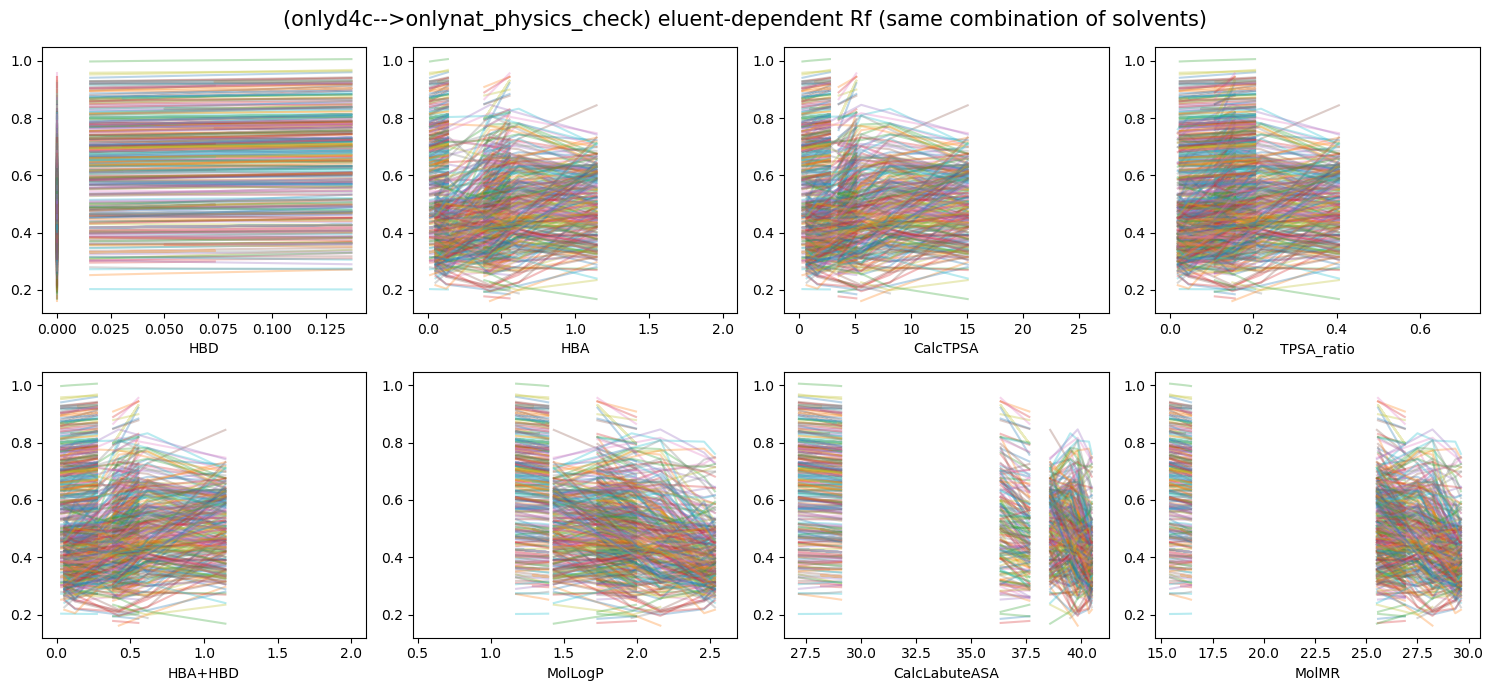

In [22]:
import matplotlib.pyplot as plt
fig,axs = plt.subplots(2,4, figsize = (15,7))

for idx,column_name in enumerate(valid_eluent_extended.columns[7:]):
    for group in pair_group_list:
        group.sort_values(by = column_name)
        x_line = group[column_name]
        y_line = group['prediction']
        axs[idx//4, idx%4].plot(x_line, y_line, alpha=0.3)
        axs[idx//4, idx%4].set_xlabel(column_name)
plt.suptitle('(onlyd4c-->onlynat_physics_check) eluent-dependent Rf (same combination of solvents)', fontsize=15)
plt.tight_layout()  # 저장 전에 레이아웃 조정해서 짤림 방지
#plt.savefig('(onlyd4c-->onlynat_physics_check)data_analysis3.png', dpi=400, bbox_inches='tight')
plt.show()

In [ ]:
# --> eluent는 전혀 파라미터 할당이 안된 듯한 모습 (비율만 고려 못하는게 아니라 용매 종류가 바뀌어도 같은 시료는 같은 예측값 내놓음)
# GCN_eluent 파라미터 확인해보면 0

HBA atom indices: ((6,), (9,), (18,))


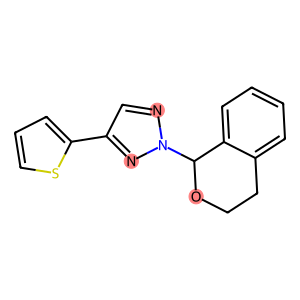

In [29]:
from rdkit import Chem
from rdkit.Chem import Draw

# 💡 수소결합 수용체 SMARTS 패턴 (위 이미지 기준)
hba_smarts = '[$([!#6;+0]);!$([F,Cl,Br,I]);!$([o,s,nX3]);!$([Nv5,Pv5,Sv4,Sv6])]'

# 예시 분자: 아세톤 (Acetone)
mol = Chem.MolFromSmiles('c1csc(-c2cnn(C3OCCc4ccccc43)n2)c1')

# SMARTS를 RDKit 패턴으로 컴파일
hba_query = Chem.MolFromSmarts(hba_smarts)

# 매칭되는 atom index 찾기
matches = mol.GetSubstructMatches(hba_query)

# 결과 출력
print("HBA atom indices:", matches)

# 🔍 시각화: 일치하는 원자 표시
atom_indices = [i[0] for i in matches]  # matches는 튜플 리스트
highlighted = Draw.MolToImage(mol, highlightAtoms=atom_indices)
highlighted.show()



In [3]:
CalcNumHBA(Chem.MolFromSmiles('c1csc(-c2cnn(C3OCCc4ccccc43)n2)c1'))

5